# PowerGuard-BD V9 — RiskPlus Contextual Mixture-of-Experts (CMoE-R+) Q1 Research Notebook

**Final proposed framework:** **PowerGuardX-CMoE-R+** — a fuel-mix-aware deep temporal core plus validation-only task-specific experts, with a dedicated **RiskPlus** classification layer designed to improve load-shedding **Accuracy and F1** without using the final test labels for tuning.

The notebook keeps the same chronological **70/15/15** split, stable Windows/Jupyter execution (`num_workers=0`), checkpoint/resume training, full comparison models, explainability, ablation, robustness analysis, and statistical testing. The final test block is touched only after all model/gate/threshold choices are frozen from training/validation data.


### V9 stability note
This version replaces the slow V7 RiskPlus exhaustive threshold/blend sweep with a compact validation-only search. It preserves the chronological split and never uses test labels for model selection.


### V9 optimization — what changed

V9 leaves the successful demand/deficit CMoE logic intact and uses the optimized RiskPlus branch for load-shedding classification.

The new **RiskPlus** branch uses: (1) probability and logit opinions from all neural/tree experts, (2) expert disagreement/consensus features, (3) leakage-safe current context built only from known exogenous variables and lagged operational history, (4) validation-only logistic/HGB/ExtraTrees stacking, (5) recency-specialist risk classifiers trained only on the training block, (6) validation-selected blends/votes, and (7) an independent calibration block for the final Accuracy/F1-focused threshold. No test target is used for architecture choice, ensemble weighting, threshold selection, or calibration.

**Important scientific rule:** the code maximizes valid out-of-sample performance but never edits predictions after seeing the test result. Therefore it can improve the probability of beating the baselines, but it does not fabricate or guarantee a particular test score.


In [ ]:
# Optional one-time installation (uncomment if needed)
# %pip install -q numpy pandas scipy scikit-learn matplotlib xgboost lightgbm shap statsmodels torch

In [1]:
import os, sys, json, math, random, warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix, roc_curve, precision_recall_curve
)
from sklearn.calibration import calibration_curve
from sklearn.ensemble import (
    RandomForestRegressor, RandomForestClassifier,
    HistGradientBoostingRegressor, HistGradientBoostingClassifier
)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.pipeline import make_pipeline

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True
torch.backends.cudnn.benchmark=False
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Windows/Jupyter stability: avoid aggressive CPU thread oversubscription.
os.environ.setdefault('OMP_NUM_THREADS','8')
os.environ.setdefault('MKL_NUM_THREADS','8')
try: torch.set_num_threads(max(1,min(8,os.cpu_count() or 1)))
except Exception: pass
try: torch.set_num_interop_threads(1)
except Exception: pass
if torch.cuda.is_available():
    # Faster fixed-shape kernels; seeds are still fixed, but exact CUDA bitwise repeatability may vary.
    torch.backends.cudnn.deterministic=False
    torch.backends.cudnn.benchmark=True
print('Python:',sys.version.split()[0], '| Torch:',torch.__version__, '| Device:',DEVICE)
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))

# Publication style: bold, high-DPI, no seaborn dependency
plt.rcParams.update({
    'figure.dpi':140,'savefig.dpi':600,'font.size':12,
    'font.weight':'bold','axes.labelweight':'bold','axes.titleweight':'bold',
    'axes.titlesize':14,'axes.labelsize':12,'legend.fontsize':10,
    'xtick.labelsize':10,'ytick.labelsize':10,'lines.linewidth':2.2
})

Python: 3.9.0 | Torch: 2.5.1+cu121 | Device: cuda
GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU


## 1. Paths and reproducible configuration

In [2]:
ROOT=Path(r'E:\P work\journal work-2')
CSV_PATH=ROOT/'Final data.csv'
if not CSV_PATH.exists():
    fallback=Path('/mnt/data/PowerGuard_BD_Merged_Research_Dataset.csv')
    if fallback.exists(): CSV_PATH=fallback
    else: raise FileNotFoundError(f'Dataset not found: {CSV_PATH}')

OUT=ROOT/'PowerGuard_BD_V9_Results' if ROOT.exists() else Path('/mnt/data/PowerGuard_BD_V9_Results')
FIG_DIR=OUT/'figures'; TABLE_DIR=OUT/'tables'; MODEL_DIR=OUT/'models'
for d in [OUT,FIG_DIR,TABLE_DIR,MODEL_DIR]: d.mkdir(parents=True,exist_ok=True)

TRAIN_FRAC=0.70; VAL_FRAC=0.15; TEST_FRAC=0.15
LAGS=[1,2,3,6,12,24,48,168]
BATCH_SIZE=128
PROPOSED_EPOCHS=100
BASELINE_EPOCHS=60
PATIENCE=15
LR=1e-4
WEIGHT_DECAY=2e-4
USE_AMP=False                 # V7: full float32 remains the safe default
FEATURE_Z_CLIP=12.0
TARGET_Z_CLIP=10.0
GRAD_CLIP=0.75
NUM_WORKERS=0                 # MUST stay 0 on Windows/Jupyter: prevents DataLoader worker deadlocks
PIN_MEMORY=False               # maximum stability; avoids a background pin-memory thread
PERSISTENT_WORKERS=False
HEARTBEAT_EVERY=100            # print within long epochs so the notebook never looks frozen
RESUME_TRAINING=True           # rerun training cell after interrupt/restart and continue from last completed epoch
SAVE_EVERY_EPOCH=True
print('Dataset:',CSV_PATH)
print('Output:',OUT)
print('AMP enabled:',USE_AMP and torch.cuda.is_available())
print(f'Loader safety: workers={NUM_WORKERS}, pin_memory={PIN_MEMORY}, batch={BATCH_SIZE}, resume={RESUME_TRAINING}')

# V9 RiskGuard controls
RISK_META_FIT_FRAC=0.60
RISK_META_SELECT_FRAC=0.20
RISK_THRESHOLD_GRID=121
RISK_SPECIALIST_RECENT_FRACS=(0.45,0.70)
RISK_BLEND_TOPK=4
RISK_BLEND_WEIGHTS=(0.30,0.50,0.70)


Dataset: E:\P work\journal work-2\Final data.csv
Output: E:\P work\journal work-2\PowerGuard_BD_V9_Results
AMP enabled: False
Loader safety: workers=0, pin_memory=False, batch=128, resume=True


### V9 execution rule (Windows/Jupyter)
Run from the top. The loader stays in the main process (`num_workers=0`) and does not use pinned-memory background threads. During training, heartbeat lines are printed every `HEARTBEAT_EVERY` batches. A resume checkpoint is saved after every completed epoch, so an interrupt/restart does not force training from epoch 1.


## 2. Dataset audit and target-regime analysis

In [3]:
df=pd.read_csv(CSV_PATH)
if 'datetime' not in df.columns: raise ValueError('Expected datetime column.')
df['datetime']=pd.to_datetime(df['datetime'],errors='coerce')
df=df.dropna(subset=['datetime']).sort_values('datetime').drop_duplicates('datetime').reset_index(drop=True)
required=['demand_mw','generation_mw','load_shedding','load_shedding_risk','power_deficit_mw']
missing=[c for c in required if c not in df.columns]
if missing: raise ValueError(f'Missing required columns: {missing}')

# hard numeric cleanup without creating target leakage
num=df.select_dtypes(include=np.number).columns
for c in num:
    df[c]=pd.to_numeric(df[c],errors='coerce').replace([np.inf,-np.inf],np.nan)
    if df[c].isna().any():
        df[c]=df[c].interpolate(limit_direction='both').ffill().bfill()

N=len(df); train_end=int(N*TRAIN_FRAC); val_end=int(N*(TRAIN_FRAC+VAL_FRAC))
print('Shape:',df.shape,' | Period:',df.datetime.min(),'to',df.datetime.max())
print('Missing cells:',int(df.isna().sum().sum()),' | Duplicate timestamps:',int(df.datetime.duplicated().sum()))
for name,a,b in [('Train',0,train_end),('Validation',train_end,val_end),('Test',val_end,N)]:
    y=df.load_shedding_risk.iloc[a:b].astype(int)
    persistence=(y.values[1:]==y.values[:-1]).mean() if len(y)>1 else np.nan
    print(f'{name:10s} n={len(y):6d} risk+={y.mean():.3%} persistence={persistence:.3%}')

audit=pd.DataFrame({
 'rows':[N],'columns':[df.shape[1]],'start':[df.datetime.min()],'end':[df.datetime.max()],
 'missing_cells':[int(df.isna().sum().sum())],'duplicate_datetime':[int(df.datetime.duplicated().sum())],
 'risk_rate':[df.load_shedding_risk.mean()],'positive_deficit_rate':[(df.power_deficit_mw>0).mean()]
})
audit.to_csv(TABLE_DIR/'dataset_audit_v7.csv',index=False)
display(audit)

Shape: (94934, 74)  | Period: 2015-04-17 18:30:00 to 2026-03-08 23:00:00
Missing cells: 0  | Duplicate timestamps: 0
Train      n= 66453 risk+=3.601% persistence=99.497%
Validation n= 14240 risk+=56.369% persistence=94.185%
Test       n= 14241 risk+=40.004% persistence=93.750%


,rows,columns,start,end,missing_cells,duplicate_datetime,risk_rate,positive_deficit_rate
0,94934,74,2015-04-17 18:30:00,2026-03-08 23:00:00,0,0,0.169771,0.169771


## 3. Unique figure — Bangladesh Energy–Weather–Risk Regime Atlas

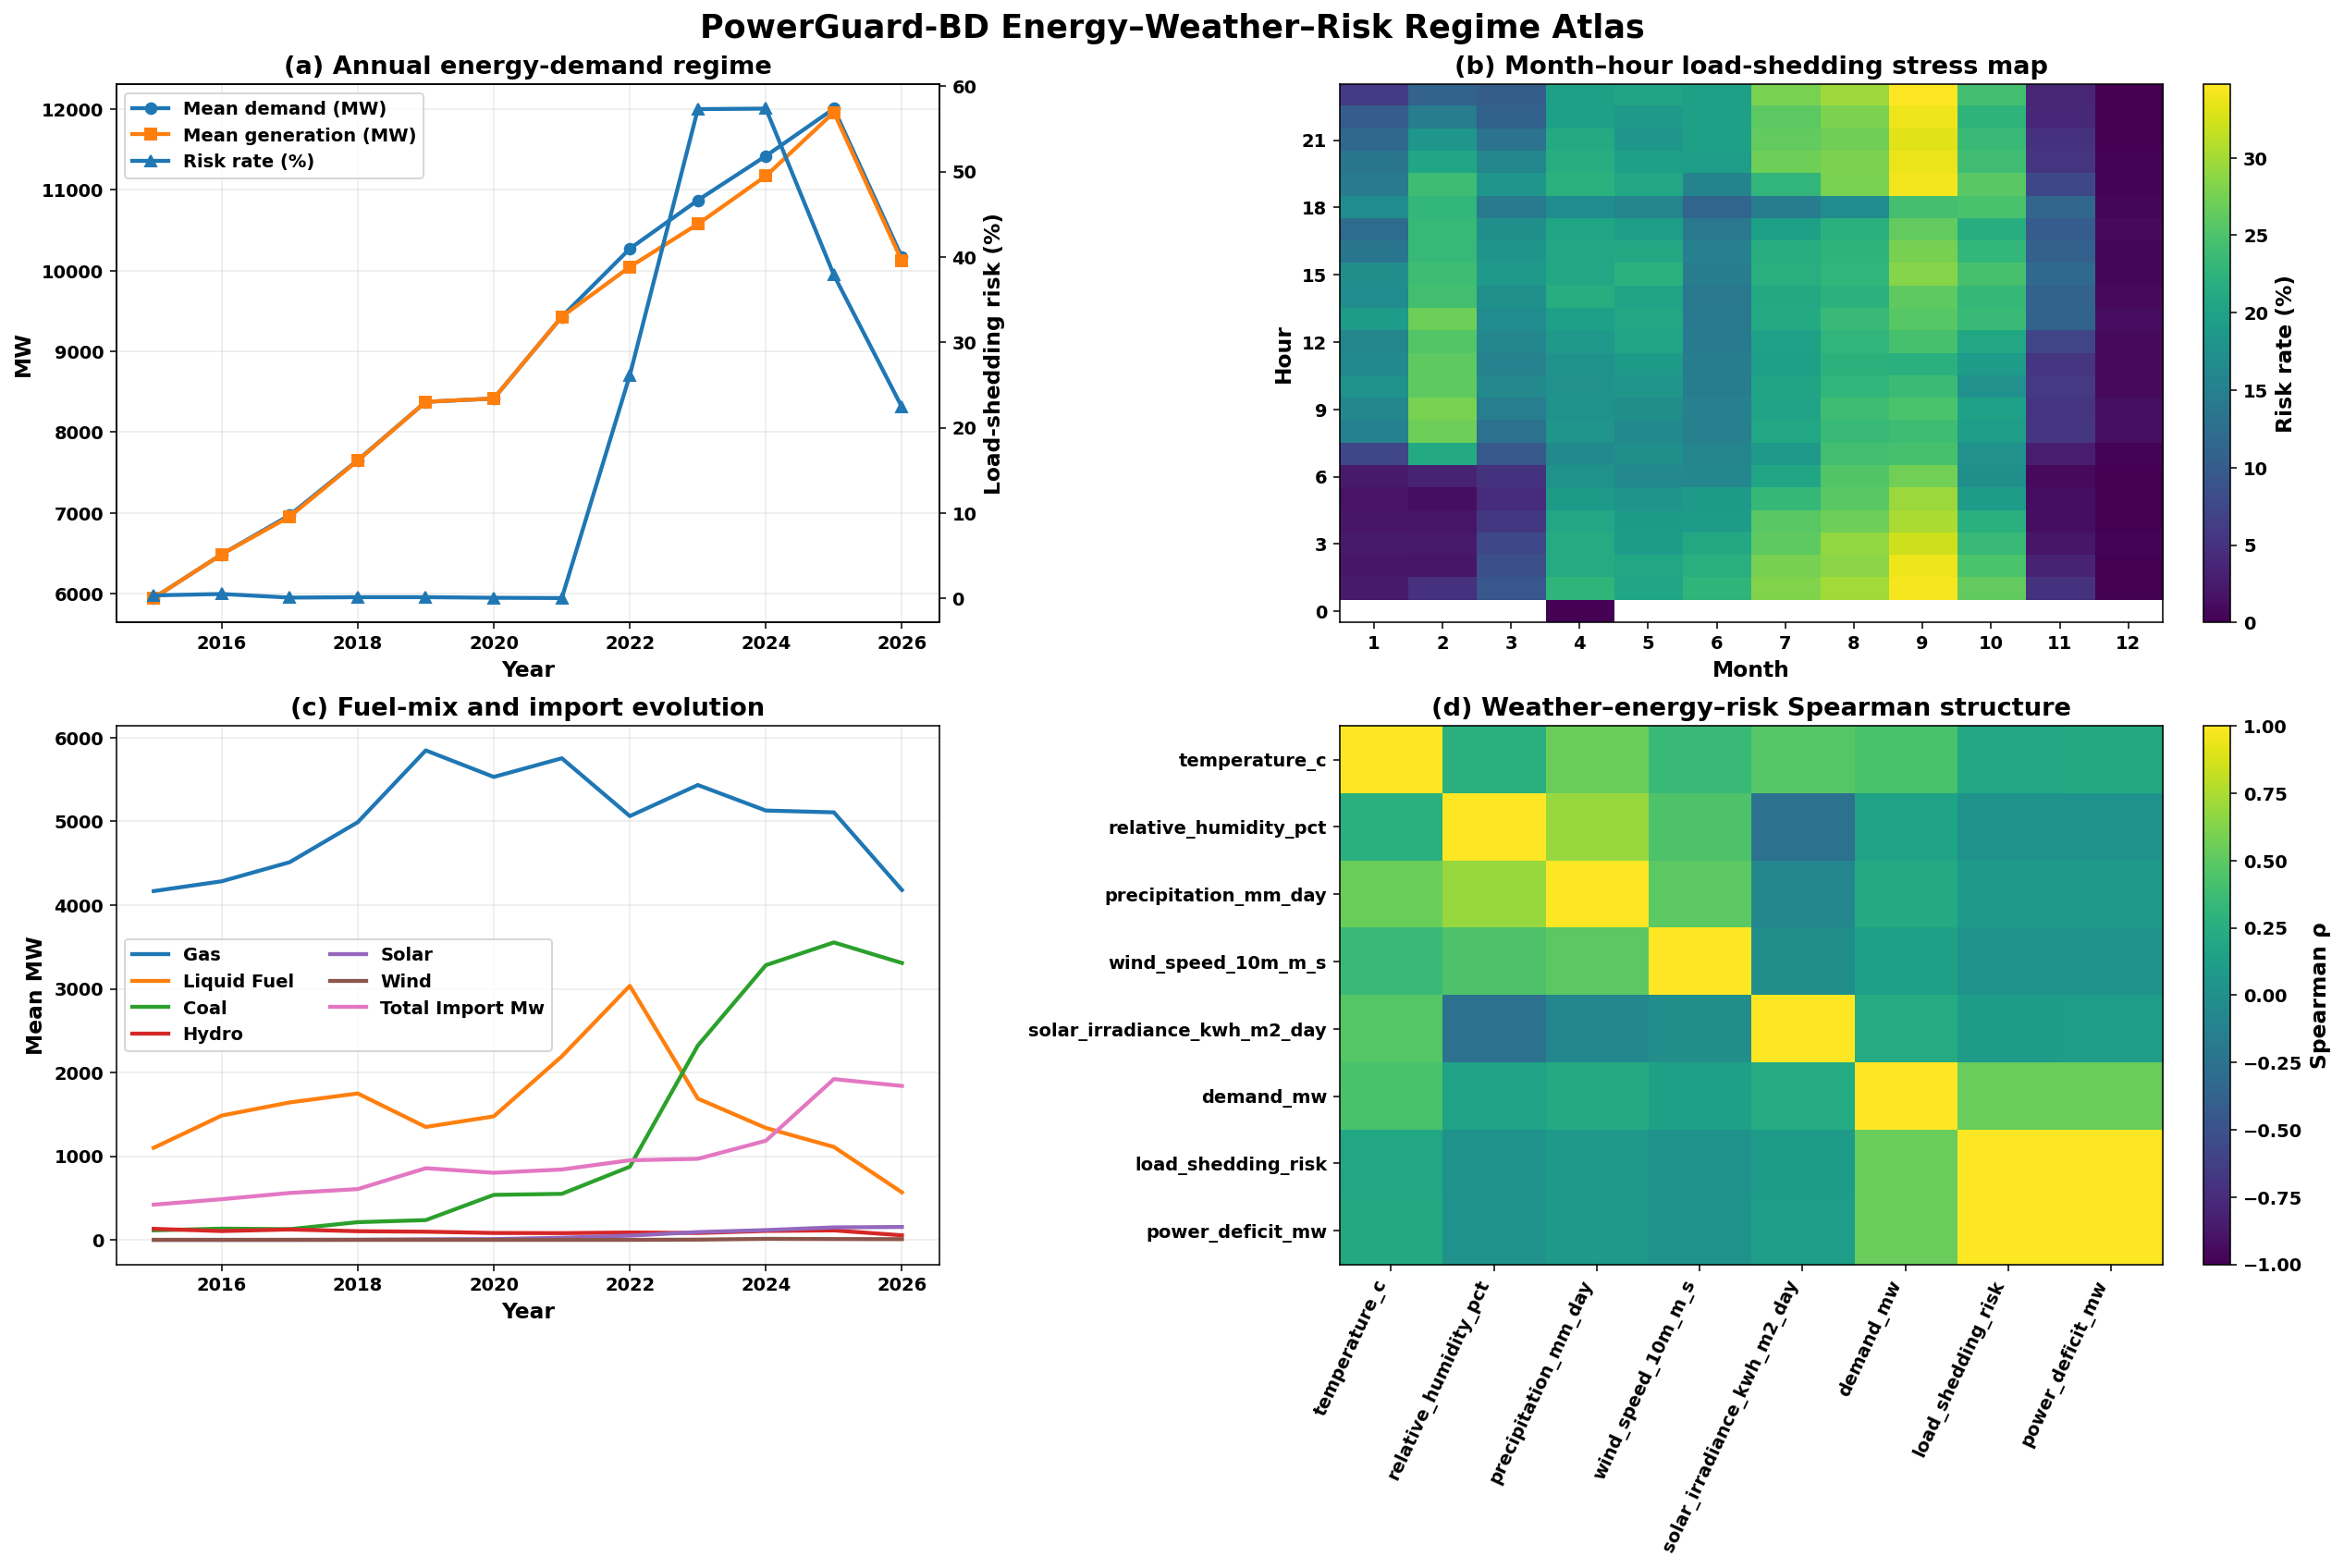

In [4]:
# Unique publication figure: yearly risk-regime + monthly-hour stress surface + fuel/weather co-movement
D=df.copy(); D['year']=D.datetime.dt.year; D['month']=D.datetime.dt.month; D['hour']=D.datetime.dt.hour
fig=plt.figure(figsize=(18,12),constrained_layout=True)
gs=fig.add_gridspec(2,2)

ax=fig.add_subplot(gs[0,0])
yr=D.groupby('year').agg(demand=('demand_mw','mean'),generation=('generation_mw','mean'),risk=('load_shedding_risk','mean'))
ax.plot(yr.index,yr.demand,label='Mean demand (MW)',marker='o')
ax.plot(yr.index,yr.generation,label='Mean generation (MW)',marker='s')
ax2=ax.twinx(); ax2.plot(yr.index,yr.risk*100,label='Risk rate (%)',marker='^')
ax.set_title('(a) Annual energy-demand regime'); ax.set_xlabel('Year'); ax.set_ylabel('MW'); ax2.set_ylabel('Load-shedding risk (%)')
lines=ax.get_lines()+ax2.get_lines(); ax.legend(lines,[l.get_label() for l in lines],loc='best')
ax.grid(alpha=.25)

ax=fig.add_subplot(gs[0,1])
piv=D.pivot_table(index='hour',columns='month',values='load_shedding_risk',aggfunc='mean')*100
im=ax.imshow(piv.values,aspect='auto',origin='lower')
ax.set_title('(b) Month–hour load-shedding stress map'); ax.set_xlabel('Month'); ax.set_ylabel('Hour')
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(0,len(piv.index),max(1,len(piv.index)//8))); ax.set_yticklabels(piv.index[::max(1,len(piv.index)//8)])
fig.colorbar(im,ax=ax,label='Risk rate (%)')

ax=fig.add_subplot(gs[1,0])
fuel_cols=[c for c in ['gas','liquid_fuel','coal','hydro','solar','wind','total_import_mw'] if c in D]
fm=D.groupby('year')[fuel_cols].mean()
for c in fm.columns: ax.plot(fm.index,fm[c],label=c.replace('_',' ').title())
ax.set_title('(c) Fuel-mix and import evolution'); ax.set_xlabel('Year'); ax.set_ylabel('Mean MW'); ax.legend(ncol=2); ax.grid(alpha=.25)

ax=fig.add_subplot(gs[1,1])
weather=[c for c in ['temperature_c','relative_humidity_pct','precipitation_mm_day','wind_speed_10m_m_s','solar_irradiance_kwh_m2_day'] if c in D]
corr=D[weather+['demand_mw','load_shedding_risk','power_deficit_mw']].corr(method='spearman')
im=ax.imshow(corr.values,vmin=-1,vmax=1,aspect='auto')
ax.set_xticks(range(len(corr.columns))); ax.set_xticklabels(corr.columns,rotation=65,ha='right')
ax.set_yticks(range(len(corr.index))); ax.set_yticklabels(corr.index)
ax.set_title('(d) Weather–energy–risk Spearman structure'); fig.colorbar(im,ax=ax,label='Spearman ρ')

fig.suptitle('PowerGuard-BD Energy–Weather–Risk Regime Atlas',fontsize=18,fontweight='bold')
fig.savefig(FIG_DIR/'Fig_01_PowerGuard_Regime_Atlas.png',bbox_inches='tight'); plt.show()

## 4. Leakage-safe multi-scale forecasting table

In [5]:
# Operational variables are shifted; current target row never sees current demand/generation/load-shedding/fuel values.
operational=[c for c in [
'demand_mw','generation_mw','load_shedding','power_deficit_mw','demand_generation_gap_mw','reserve_margin_proxy_pct',
'gas','liquid_fuel','coal','hydro','solar','wind','india_bheramara_hvdc','india_tripura','india_adani','nepal',
'fossil_generation_mw','renewable_generation_mw','total_import_mw','accounted_supply_mw'
] if c in df.columns]
known_exog=[c for c in [
'hour_sin','hour_cos','dow_sin','dow_cos','month_sin','month_cos','is_weekend','hour','month','day_of_week',
'temperature_c','temperature_max_c','temperature_min_c','relative_humidity_pct','precipitation_mm_day','wind_speed_10m_m_s','solar_irradiance_kwh_m2_day'
] if c in df.columns]

lag_frames=[]
for lag in LAGS:
    z=df[operational].shift(lag).copy(); z.columns=[f'{c}__lag{lag}' for c in operational]; lag_frames.append(z)
flat=pd.concat(lag_frames+[df[known_exog]],axis=1)
flat['seasonal_naive_demand']=df['demand_mw'].shift(24)
flat['prev_risk']=df['load_shedding_risk'].shift(1)
flat['prev_deficit']=df['power_deficit_mw'].shift(1)
flat['risk_run_6']=df['load_shedding_risk'].shift(1).rolling(6,min_periods=1).mean()
flat['risk_run_24']=df['load_shedding_risk'].shift(1).rolling(24,min_periods=1).mean()
flat['demand_roll24_mean']=df['demand_mw'].shift(1).rolling(24,min_periods=1).mean()
flat['demand_roll24_std']=df['demand_mw'].shift(1).rolling(24,min_periods=2).std().fillna(0)

valid=np.arange(len(df))>=max(LAGS)
M=df.loc[valid,['datetime','demand_mw','load_shedding_risk','power_deficit_mw']].reset_index(drop=True)
Xflat=flat.loc[valid].reset_index(drop=True).replace([np.inf,-np.inf],np.nan).ffill().bfill().fillna(0)
base_idx=np.where(valid)[0]

tr_mask=base_idx<train_end; va_mask=(base_idx>=train_end)&(base_idx<val_end); te_mask=base_idx>=val_end
print('Samples:',len(M),'| train/val/test:',tr_mask.sum(),va_mask.sum(),te_mask.sum())

# Robust feature scaling fit ONLY on train. V4 then clips standardized values to stop extreme derived columns
# (e.g. reserve-margin proxy) from creating million-scale activations.
x_scaler=RobustScaler(quantile_range=(5,95)).fit(Xflat.loc[tr_mask])
Xz=x_scaler.transform(Xflat).astype('float32')
Xz=np.nan_to_num(Xz,nan=0.0,posinf=FEATURE_Z_CLIP,neginf=-FEATURE_Z_CLIP)
Xz=np.clip(Xz,-FEATURE_Z_CLIP,FEATURE_Z_CLIP).astype('float32')
assert np.isfinite(Xz).all(), 'Non-finite feature after V4 scaling.'

K=len(operational); L=len(LAGS)
Xhist=Xz[:,:K*L].reshape(len(Xz),L,K)
Xexo=Xz[:,K*L:]
exo_names=list(Xflat.columns[K*L:])

# Demand target: residual over a seasonal-naive baseline, train-fitted robust scale, bounded standardized target.
seasonal_base=Xflat['seasonal_naive_demand'].to_numpy('float32')
y_d=M.demand_mw.to_numpy('float32')
y_d_res=y_d-seasonal_base
res_scaler=RobustScaler(quantile_range=(5,95)).fit(y_d_res[tr_mask].reshape(-1,1))
y_dz=res_scaler.transform(y_d_res.reshape(-1,1)).ravel().astype('float32')
y_dz=np.clip(np.nan_to_num(y_dz,nan=0.0,posinf=TARGET_Z_CLIP,neginf=-TARGET_Z_CLIP),-TARGET_Z_CLIP,TARGET_Z_CLIP)

# Two-part hurdle target for deficit: classifier predicts occurrence; regressor predicts log-magnitude only for positives.
raw_def=M.power_deficit_mw.to_numpy('float32')
y_r=M.load_shedding_risk.to_numpy('float32')
pos_train=(raw_def[tr_mask]>0)
if pos_train.sum()==0: raise ValueError('No positive deficit samples in training split.')
mag_scaler=RobustScaler(quantile_range=(5,95)).fit(np.log1p(raw_def[tr_mask][pos_train]).reshape(-1,1))
y_mag=np.zeros(len(M),dtype='float32')
pos=raw_def>0
y_mag[pos]=mag_scaler.transform(np.log1p(raw_def[pos]).reshape(-1,1)).ravel().astype('float32')
y_mag=np.clip(np.nan_to_num(y_mag,nan=0.0,posinf=TARGET_Z_CLIP,neginf=-TARGET_Z_CLIP),-TARGET_Z_CLIP,TARGET_Z_CLIP)

# Train-only physical caps used only as safety guards during inverse transforms (not for tuning on test).
DEMAND_CAP=float(max(1.0,np.nanmax(y_d[tr_mask])*1.50))
DEFICIT_CAP=float(max(1.0,np.nanmax(raw_def[tr_mask])*1.50))
DEMAND_Z_LOW=float(np.nanmin(y_dz[tr_mask])-1.0); DEMAND_Z_HIGH=float(np.nanmax(y_dz[tr_mask])+1.0)
MAG_Z_LOW=float(np.nanmin(y_mag[tr_mask])-1.0); MAG_Z_HIGH=float(np.nanmax(y_mag[tr_mask])+1.0)

print('History tensor:',Xhist.shape,'| Exogenous:',Xexo.shape,'| operational features:',K)
print('Feature z-range:',float(Xz.min()),float(Xz.max()))
print('Demand target z-range:',float(y_dz.min()),float(y_dz.max()),'| Mag target z-range:',float(y_mag.min()),float(y_mag.max()))
print('Train-only safety caps -> demand:',DEMAND_CAP,'MW | deficit:',DEFICIT_CAP,'MW')


Samples: 94766 | train/val/test: 66285 14240 14241
History tensor: (94766, 8, 20) | Exogenous: (94766, 24) | operational features: 20
Feature z-range: -12.0 12.0
Demand target z-range: -10.0 10.0 | Mag target z-range: -1.9335988759994507 1.4883373975753784
Train-only safety caps -> demand: 121033.5 MW | deficit: 98038.5 MW


## 5. Distribution-shift diagnostics and regime weights

In [6]:
for name,m in [('Train',tr_mask),('Validation',va_mask),('Test',te_mask)]:
    print(name,'risk prevalence=',f'{y_r[m].mean():.2%}','n=',m.sum())

# V4: recency weights only. Class imbalance is handled in BCE once (Cell 21), avoiding V3 double weighting.
idx=np.where(tr_mask)[0]
recency=np.exp(1.25*np.linspace(0,1,len(idx))).astype('float32')
train_weights=recency/recency.mean()
train_weights=np.clip(train_weights,0.50,2.50).astype('float32')
train_weights/=train_weights.mean()
print('Recency-only weight range:',float(train_weights.min()),float(train_weights.max()))


Train risk prevalence= 3.61% n= 66285
Validation risk prevalence= 56.37% n= 14240
Test risk prevalence= 40.00% n= 14241
Recency-only weight range: 0.5019379258155823 1.751935362815857


## 6. PyTorch datasets

In [7]:
class PGDataset(Dataset):
    def __init__(self,mask,weights=None):
        self.ids=np.where(mask)[0]
        self.weights=np.ones(len(self.ids),np.float32) if weights is None else weights.astype('float32')
    def __len__(self): return len(self.ids)
    def __getitem__(self,i):
        j=self.ids[i]
        return (torch.from_numpy(Xhist[j]),torch.from_numpy(Xexo[j]),torch.tensor(y_dz[j]),torch.tensor(y_r[j]),
                torch.tensor(y_mag[j]),torch.tensor(float(pos[j])),torch.tensor(self.weights[i]),torch.tensor(j))

tr_ds=PGDataset(tr_mask,train_weights); va_ds=PGDataset(va_mask); te_ds=PGDataset(te_mask)
loader_kw=dict(batch_size=BATCH_SIZE,num_workers=NUM_WORKERS,pin_memory=PIN_MEMORY)
# persistent_workers is valid only when num_workers > 0.
if NUM_WORKERS>0: loader_kw['persistent_workers']=PERSISTENT_WORKERS
tr_loader=DataLoader(tr_ds,shuffle=True,**loader_kw)
va_loader=DataLoader(va_ds,shuffle=False,**loader_kw)
te_loader=DataLoader(te_ds,shuffle=False,**loader_kw)
print('DataLoaders created in main process (Windows-safe).')
print(len(tr_ds),len(va_ds),len(te_ds))

DataLoaders created in main process (Windows-safe).
66285 14240 14241


## 7. Proposed model — PowerGuard-X (RA-FM-MTT)

In [8]:
# operational-group indices within each history token
fuel_names=[c for c in ['gas','liquid_fuel','coal','hydro','solar','wind','india_bheramara_hvdc','india_tripura','india_adani','nepal','total_import_mw'] if c in operational]
fuel_idx=[operational.index(c) for c in fuel_names]
weather_exo_idx=[exo_names.index(c) for c in ['temperature_c','temperature_max_c','temperature_min_c','relative_humidity_pct','precipitation_mm_day','wind_speed_10m_m_s','solar_irradiance_kwh_m2_day'] if c in exo_names]

def bounded_regression(x,limit=TARGET_Z_CLIP):
    return limit*torch.tanh(x/limit)

class GRN(nn.Module):
    def __init__(self,d,drop=.12):
        super().__init__(); self.a=nn.Linear(d,d*2); self.b=nn.Linear(d,d); self.norm=nn.LayerNorm(d); self.drop=nn.Dropout(drop)
    def forward(self,x):
        u,v=self.a(x).chunk(2,-1); h=F.silu(u)*torch.sigmoid(v); return self.norm(x+self.drop(self.b(h)))

class PowerGuardX(nn.Module):
    def __init__(self,k_hist,k_exo,d=160,heads=8,layers=3,drop=.12):
        super().__init__()
        self.feature_gate=nn.Sequential(nn.Linear(k_hist,k_hist),nn.Sigmoid())
        self.hist_proj=nn.Linear(k_hist,d)
        self.lag_embed=nn.Parameter(torch.randn(1,len(LAGS),d)*0.02)
        enc=nn.TransformerEncoderLayer(d_model=d,nhead=heads,dim_feedforward=d*4,dropout=drop,batch_first=True,norm_first=True,activation='gelu')
        self.encoder=nn.TransformerEncoder(enc,num_layers=layers)
        self.exo=nn.Sequential(nn.Linear(k_exo,d),nn.LayerNorm(d),nn.GELU(),nn.Dropout(drop),GRN(d,drop))
        self.fuel=nn.Sequential(nn.Linear(max(1,len(fuel_idx)),d),nn.LayerNorm(d),nn.GELU(),nn.Dropout(drop),GRN(d,drop))
        self.attn_pool=nn.Sequential(nn.Linear(d,d//2),nn.Tanh(),nn.Linear(d//2,1))
        self.fusion=nn.Sequential(nn.Linear(d*3,d),GRN(d,drop),nn.Dropout(drop),nn.Linear(d,d),GRN(d,drop))
        self.demand_head=nn.Sequential(nn.Linear(d,96),nn.GELU(),nn.Dropout(drop),nn.Linear(96,1))
        self.risk_head=nn.Sequential(nn.Linear(d,96),nn.GELU(),nn.Dropout(drop),nn.Linear(96,1))
        self.mag_head=nn.Sequential(nn.Linear(d,96),nn.GELU(),nn.Dropout(drop),nn.Linear(96,1))
        self.log_vars=nn.Parameter(torch.zeros(3))
    def forward(self,hist,exo,return_aux=False):
        g=self.feature_gate(hist)
        z=self.hist_proj(hist*g)+self.lag_embed
        z=self.encoder(z)
        a=torch.softmax(self.attn_pool(z).squeeze(-1),dim=1)
        ctx=(z*a.unsqueeze(-1)).sum(1)
        fuel=hist[:,-1,fuel_idx] if fuel_idx else hist[:,-1,:1]
        fctx=self.fuel(fuel)
        ectx=self.exo(exo)
        s=self.fusion(torch.cat([ctx,fctx,ectx],-1))
        out=(bounded_regression(self.demand_head(s).squeeze(-1)),self.risk_head(s).squeeze(-1),bounded_regression(self.mag_head(s).squeeze(-1)))
        if return_aux: return (*out,a,g)
        return out

proposed=PowerGuardX(K,Xexo.shape[1]).to(DEVICE)
print(proposed)
print('Trainable params:',sum(p.numel() for p in proposed.parameters() if p.requires_grad))

PowerGuardX(
  (feature_gate): Sequential(
    (0): Linear(in_features=20, out_features=20, bias=True)
    (1): Sigmoid()
  )
  (hist_proj): Linear(in_features=20, out_features=160, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=160, out_features=160, bias=True)
        )
        (linear1): Linear(in_features=160, out_features=640, bias=True)
        (dropout): Dropout(p=0.12, inplace=False)
        (linear2): Linear(in_features=640, out_features=160, bias=True)
        (norm1): LayerNorm((160,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((160,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.12, inplace=False)
        (dropout2): Dropout(p=0.12, inplace=False)
      )
    )
  )
  (exo): Sequential(
    (0): Linear(in_features=24, out_features=160, bias=True)
    (1): LayerNor

## 8. Neural comparison models

In [9]:
class Heads(nn.Module):
    def __init__(self,d):
        super().__init__(); self.d=nn.Linear(d,1); self.r=nn.Linear(d,1); self.m=nn.Linear(d,1)
    def forward(self,z):
        d=bounded_regression(self.d(z).squeeze(-1))
        r=self.r(z).squeeze(-1)
        m=bounded_regression(self.m(z).squeeze(-1))
        return d,r,m

class VanillaTransformer(nn.Module):
    def __init__(self,d=128):
        super().__init__(); self.p=nn.Linear(K,d); layer=nn.TransformerEncoderLayer(d,8,d*4,.12,batch_first=True,norm_first=True,activation='gelu'); self.t=nn.TransformerEncoder(layer,2); self.ex=nn.Sequential(nn.Linear(Xexo.shape[1],d),nn.LayerNorm(d)); self.h=Heads(d)
    def forward(self,x,e):
        z=self.t(self.p(x)).mean(1)+self.ex(e); return self.h(z)

builders={
 'Vanilla_Transformer':lambda:VanillaTransformer(),'PowerGuardX_Proposed':lambda:PowerGuardX(K,Xexo.shape[1])
}


## 9. Stable multi-task loss and training engine

In [10]:
# V7: numerically stable + Windows/Jupyter-safe training with heartbeat and epoch-level resume checkpoints.
p=float(y_r[tr_mask].mean())
raw_ratio=(1-p)/max(p,1e-6)
pos_weight=float(np.clip(np.sqrt(raw_ratio),1.0,6.0))
pos_weight_t=torch.tensor(pos_weight,dtype=torch.float32,device=DEVICE)
print('BCE positive weight:',pos_weight)

TASK_W=torch.tensor([1.0,1.0,0.60],dtype=torch.float32,device=DEVICE)

def loss_fn(model,out,yd,yr,ym,ispos,w):
    pd_,pr_,pm_=out
    pd_=torch.nan_to_num(pd_,nan=0.0,posinf=TARGET_Z_CLIP,neginf=-TARGET_Z_CLIP).clamp(-TARGET_Z_CLIP,TARGET_Z_CLIP)
    pr_=torch.nan_to_num(pr_,nan=0.0,posinf=30.0,neginf=-30.0).clamp(-30,30)
    pm_=torch.nan_to_num(pm_,nan=0.0,posinf=TARGET_Z_CLIP,neginf=-TARGET_Z_CLIP).clamp(-TARGET_Z_CLIP,TARGET_Z_CLIP)

    ld=F.smooth_l1_loss(pd_,yd,reduction='none',beta=0.5)
    lr=F.binary_cross_entropy_with_logits(pr_,yr,pos_weight=pos_weight_t,reduction='none')
    mag_each=F.smooth_l1_loss(pm_,ym,reduction='none',beta=0.5)
    if bool((ispos>0.5).any()):
        lm=(mag_each*w*ispos).sum()/((w*ispos).sum().clamp_min(1.0))
    else:
        lm=mag_each.sum()*0.0
    ld=(ld*w).mean(); lr=(lr*w).mean()
    losses=torch.stack([ld,lr,lm])
    total=(TASK_W*losses).sum()
    return total,losses.detach()

@torch.no_grad()
def eval_loss(model,loader):
    model.eval(); s=np.zeros(4,dtype=np.float64); n=0
    for h,e,yd,yr,ym,ip,w,j in loader:
        h,e,yd,yr,ym,ip,w=[q.to(DEVICE,dtype=torch.float32) for q in [h,e,yd,yr,ym,ip,w]]
        total,parts=loss_fn(model,model(h,e),yd,yr,ym,ip,w)
        b=len(h); vals=np.array([float(total.item()),*parts.cpu().numpy().astype(float)])
        if np.isfinite(vals).all(): s+=vals*b; n+=b
    return s/max(n,1)

def _finite_grads(model):
    for p in model.parameters():
        if p.grad is not None and not torch.isfinite(p.grad).all(): return False
    return True

def _torch_load(path,map_location=None,weights_only=None):
    kwargs={'map_location':map_location}
    if weights_only is not None: kwargs['weights_only']=weights_only
    try: return torch.load(path,**kwargs)
    except TypeError:
        kwargs.pop('weights_only',None); return torch.load(path,**kwargs)

def _save_resume(path,model,opt,sch,epoch,best,bad,hist,skipped):
    tmp=Path(str(path)+'.tmp')
    torch.save({
        'epoch':int(epoch),'model':model.state_dict(),'optimizer':opt.state_dict(),'scheduler':sch.state_dict(),
        'best':float(best),'bad':int(bad),'hist':hist,'skipped':int(skipped)
    },tmp)
    os.replace(tmp,path)

def fit_neural(name,model,max_epochs):
    import time, gc
    model=model.to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY,betas=(0.9,0.98),eps=1e-7)
    sch=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=0.5,patience=4,min_lr=2e-6)
    amp_enabled=bool(USE_AMP and torch.cuda.is_available())
    scaler=torch.amp.GradScaler('cuda',enabled=amp_enabled)

    best_path=MODEL_DIR/f'{name}_best.pt'
    resume_path=MODEL_DIR/f'{name}_resume.pt'
    best=np.inf; bad=0; hist=[]; skipped=0; start_epoch=1

    # A valid starting checkpoint always exists.
    if not best_path.exists(): torch.save(model.state_dict(),best_path)

    # Resume only from this V7 output folder. If an epoch was interrupted, the previous completed epoch is preserved.
    if RESUME_TRAINING and resume_path.exists():
        try:
            ck=_torch_load(resume_path,map_location=DEVICE,weights_only=False)
            model.load_state_dict(ck['model']); opt.load_state_dict(ck['optimizer']); sch.load_state_dict(ck['scheduler'])
            best=float(ck.get('best',np.inf)); bad=int(ck.get('bad',0)); hist=list(ck.get('hist',[])); skipped=int(ck.get('skipped',0))
            start_epoch=int(ck.get('epoch',0))+1
            print(f'RESUME {name}: completed epoch {start_epoch-1}; continuing at {start_epoch}/{max_epochs}',flush=True)
        except Exception as ex:
            print(f'WARNING: resume checkpoint ignored for {name}: {ex}',flush=True)
            start_epoch=1; best=np.inf; bad=0; hist=[]; skipped=0

    if start_epoch>max_epochs:
        print(f'{name}: training already complete in checkpoint.',flush=True)
        model.load_state_dict(_torch_load(best_path,map_location=DEVICE,weights_only=True))
        H=pd.DataFrame(hist); H.to_csv(TABLE_DIR/f'{name}_history.csv',index=False)
        return model,H

    total_batches=len(tr_loader)
    for ep in range(start_epoch,max_epochs+1):
        ep_t0=time.time(); model.train(); s=np.zeros(4,dtype=np.float64); n=0; ep_skipped=0
        for bi,(h,e,yd,yr,ym,ip,w,j) in enumerate(tr_loader,1):
            h,e,yd,yr,ym,ip,w=[q.to(DEVICE,dtype=torch.float32) for q in [h,e,yd,yr,ym,ip,w]]
            if not all(torch.isfinite(q).all() for q in [h,e,yd,yr,ym,ip,w]):
                ep_skipped+=1; continue
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda',enabled=amp_enabled):
                out=model(h,e); total,parts=loss_fn(model,out,yd,yr,ym,ip,w)
            if not torch.isfinite(total):
                ep_skipped+=1; opt.zero_grad(set_to_none=True); continue
            scaler.scale(total).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(),GRAD_CLIP,error_if_nonfinite=False)
            if not _finite_grads(model):
                ep_skipped+=1; opt.zero_grad(set_to_none=True); scaler.update(); continue
            scaler.step(opt); scaler.update()
            b=len(h); vals=np.array([float(total.item()),*parts.cpu().numpy().astype(float)])
            if np.isfinite(vals).all(): s+=vals*b; n+=b

            # In-epoch heartbeat: confirms the kernel is alive even when one epoch is long.
            if HEARTBEAT_EVERY and (bi%HEARTBEAT_EVERY==0 or bi==total_batches):
                elapsed=time.time()-ep_t0
                msg=f'{name:24s} ep {ep:03d} batch {bi:04d}/{total_batches:04d} elapsed={elapsed/60:.1f}m'
                if torch.cuda.is_available():
                    msg+=f' gpu_mem={torch.cuda.memory_allocated()/1024**3:.2f}GB'
                print(msg,flush=True)

        tr=s/max(n,1); va=eval_loss(model,va_loader)
        sch.step(float(va[0]) if np.isfinite(va[0]) else 1e9)
        row={'epoch':ep,'train_total':tr[0],'train_demand':tr[1],'train_risk':tr[2],'train_mag':tr[3],
             'val_total':va[0],'val_demand':va[1],'val_risk':va[2],'val_mag':va[3],
             'lr':opt.param_groups[0]['lr'],'skipped_batches':ep_skipped,'epoch_seconds':time.time()-ep_t0}
        hist.append(row); skipped+=ep_skipped
        print(f'{name:24s} ep {ep:03d} DONE train={tr[0]:.5f} val={va[0]:.5f} lr={row["lr"]:.2e} skipped={ep_skipped} time={row["epoch_seconds"]/60:.1f}m',flush=True)

        if np.isfinite(va[0]) and va[0]<best-1e-4:
            best=float(va[0]); bad=0; torch.save(model.state_dict(),best_path)
        else:
            bad+=1

        if SAVE_EVERY_EPOCH:
            _save_resume(resume_path,model,opt,sch,ep,best,bad,hist,skipped)
        pd.DataFrame(hist).to_csv(TABLE_DIR/f'{name}_history.csv',index=False)

        if bad>=PATIENCE:
            print(f'{name}: early stopping at epoch {ep}; best val={best:.5f}',flush=True)
            break

    model.load_state_dict(_torch_load(best_path,map_location=DEVICE,weights_only=True))
    H=pd.DataFrame(hist); H.to_csv(TABLE_DIR/f'{name}_history.csv',index=False)
    print(f'{name}: best finite val={best:.5f}, total skipped batches={skipped}',flush=True)
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return model,H


BCE positive weight: 5.167159656045159


## 10. Train neural models

In [11]:
# === V7 PRE-FLIGHT + OPTIMIZER STRESS TEST ===
_batch=next(iter(tr_loader))
_h,_e,_yd,_yr,_ym,_ip,_w,_j=_batch
_h,_e,_yd,_yr,_ym,_ip,_w=[q.to(DEVICE,dtype=torch.float32) for q in [_h,_e,_yd,_yr,_ym,_ip,_w]]
for _name,_builder in builders.items():
    _m=_builder().to(DEVICE); _m.train(); _opt=torch.optim.AdamW(_m.parameters(),lr=LR)
    _last=None
    for _step in range(3):
        _opt.zero_grad(set_to_none=True); _out=_m(_h,_e); _tot,_parts=loss_fn(_m,_out,_yd,_yr,_ym,_ip,_w)
        assert torch.isfinite(_tot), f'{_name}: non-finite preflight loss at step {_step}'
        _tot.backward(); nn.utils.clip_grad_norm_(_m.parameters(),GRAD_CLIP)
        assert _finite_grads(_m), f'{_name}: non-finite gradient at step {_step}'
        _opt.step(); _last=float(_tot.item())
    with torch.no_grad():
        _out=_m(_h,_e); _tot,_parts=loss_fn(_m,_out,_yd,_yr,_ym,_ip,_w)
    assert len(_out)==3 and torch.isfinite(_tot), f'{_name}: invalid post-step output'
    print(f'{_name:24s} 3-step stress test OK | loss={_tot.item():.5f} | parts={_parts.cpu().numpy()}')
    del _m,_opt,_out,_tot,_parts
    if torch.cuda.is_available(): torch.cuda.empty_cache()
print('All neural architectures passed V7 finite forward/backward/optimizer checks.')


Vanilla_Transformer      3-step stress test OK | loss=1.53422 | parts=[0.25699377 0.6190505  1.0969627 ]
PowerGuardX_Proposed     3-step stress test OK | loss=0.84167 | parts=[0.09442677 0.6288573  0.19730237]
All neural architectures passed V7 finite forward/backward/optimizer checks.


In [12]:
import gc
trained={}; histories={}
TRAIN_ORDER=['PowerGuardX_Proposed','Vanilla_Transformer']
for name in TRAIN_ORDER:
    b=builders[name]
    print('\n'+'='*110+'\n'+name+'\n'+'='*110,flush=True)
    epochs=PROPOSED_EPOCHS if name=='PowerGuardX_Proposed' else BASELINE_EPOCHS
    trained[name],histories[name]=fit_neural(name,b(),epochs)
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
print('\nALL neural training finished (or resumed to completion).',flush=True)



PowerGuardX_Proposed
RESUME PowerGuardX_Proposed: completed epoch 26; continuing at 27/100
PowerGuardX_Proposed     ep 027 batch 0100/0518 elapsed=0.1m gpu_mem=0.05GB
PowerGuardX_Proposed     ep 027 batch 0200/0518 elapsed=0.2m gpu_mem=0.05GB
PowerGuardX_Proposed     ep 027 batch 0300/0518 elapsed=0.4m gpu_mem=0.05GB
PowerGuardX_Proposed     ep 027 batch 0400/0518 elapsed=0.5m gpu_mem=0.05GB
PowerGuardX_Proposed     ep 027 batch 0500/0518 elapsed=0.6m gpu_mem=0.05GB
PowerGuardX_Proposed     ep 027 batch 0518/0518 elapsed=0.6m gpu_mem=0.05GB
PowerGuardX_Proposed     ep 027 DONE train=0.08793 val=0.93661 lr=1.25e-05 skipped=0 time=0.6m
PowerGuardX_Proposed: early stopping at epoch 27; best val=0.62758
PowerGuardX_Proposed: best finite val=0.62758, total skipped batches=0

Vanilla_Transformer
RESUME Vanilla_Transformer: completed epoch 30; continuing at 31/60
Vanilla_Transformer      ep 031 batch 0100/0518 elapsed=0.1m gpu_mem=0.04GB
Vanilla_Transformer      ep 031 batch 0200/0518 elapse

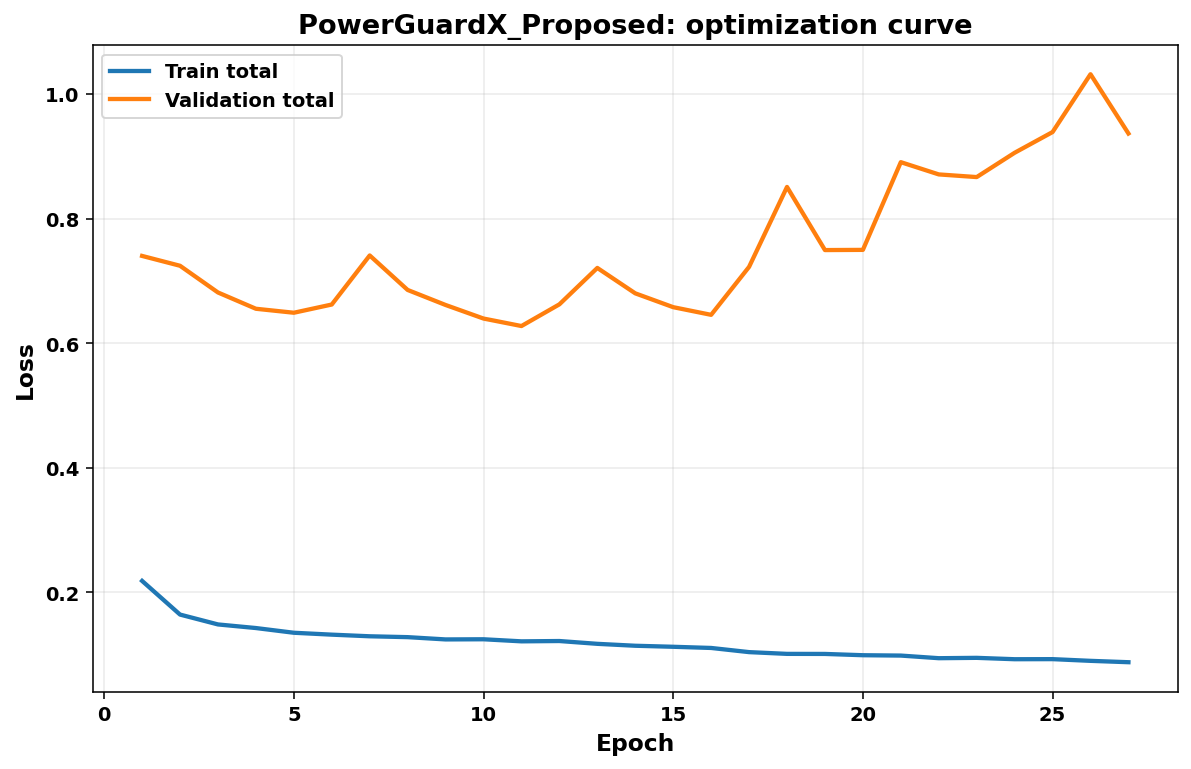

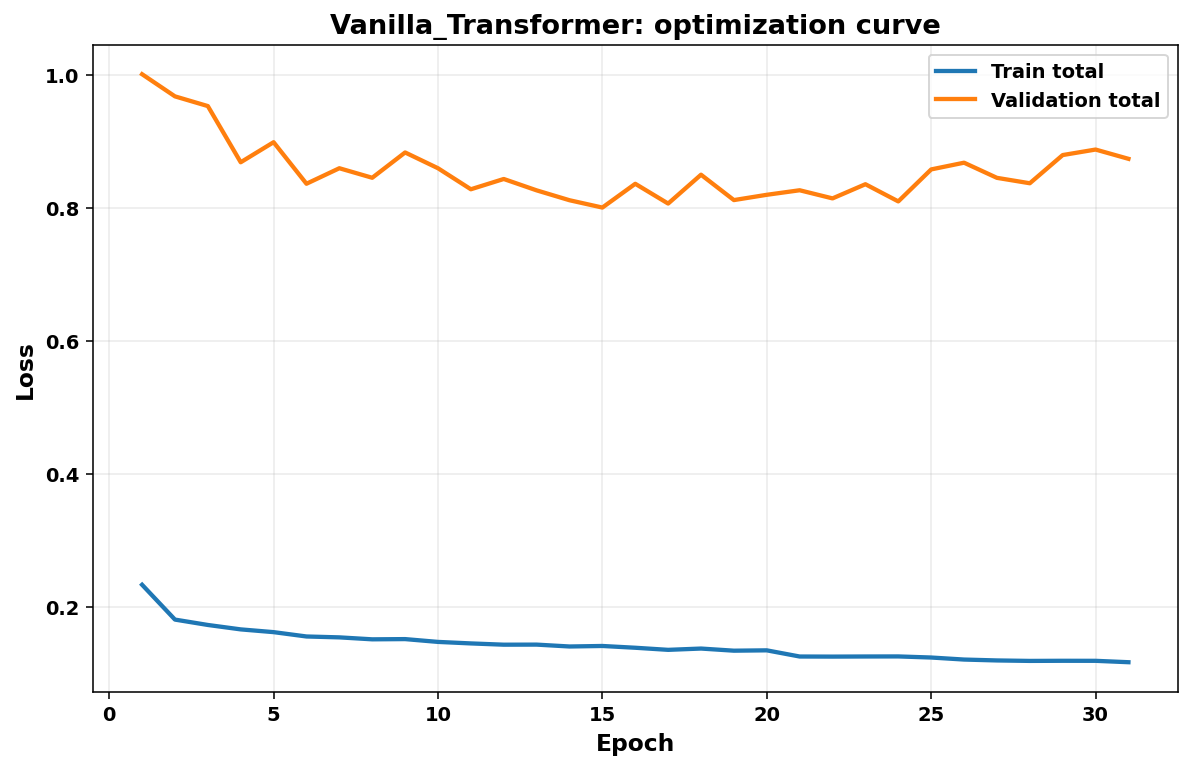

In [13]:
for name,H in histories.items():
    fig,ax=plt.subplots(figsize=(10,6))
    ax.plot(H.epoch,H.train_total,label='Train total')
    ax.plot(H.epoch,H.val_total,label='Validation total')
    ax.set_title(f'{name}: optimization curve'); ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.grid(alpha=.25); ax.legend()
    fig.savefig(FIG_DIR/f'TrainCurve_{name}.png',bbox_inches='tight'); plt.show()

## 11. Bold training curves

**V9 stability note.** `NUM_WORKERS=0`, `PIN_MEMORY=False`, in-epoch heartbeat messages, and epoch-level resume checkpoints are intentional for Windows + Jupyter reliability. If execution is interrupted, rerun the training cell; each model resumes from its last completed epoch.


## 12. Prediction helpers, inverse transforms, validation threshold tuning

In [14]:
def _finite_np(a,lo=None,hi=None):
    a=np.asarray(a,dtype=np.float64)
    a=np.nan_to_num(a,nan=0.0,posinf=(hi if hi is not None else 0.0),neginf=(lo if lo is not None else 0.0))
    if lo is not None or hi is not None: a=np.clip(a,lo,hi)
    return a

def inv_demand(z,ids):
    z=_finite_np(z,DEMAND_Z_LOW,DEMAND_Z_HIGH)
    residual=res_scaler.inverse_transform(z.reshape(-1,1)).ravel()
    pred=_finite_np(seasonal_base[np.asarray(ids,dtype=int)]+residual,0.0,DEMAND_CAP)
    return pred

def inv_mag(z):
    z=_finite_np(z,MAG_Z_LOW,MAG_Z_HIGH)
    logv=mag_scaler.inverse_transform(z.reshape(-1,1)).ravel()
    # log-domain cap before expm1 guarantees no overflow
    log_cap=float(np.log1p(DEFICIT_CAP))
    logv=_finite_np(logv,0.0,log_cap)
    v=np.expm1(logv)
    return _finite_np(v,0.0,DEFICIT_CAP)

@torch.no_grad()
def predict_neural(model,loader):
    model.eval(); ids=[]; dz=[]; rp=[]; mz=[]
    for h,e,yd,yr,ym,ip,w,j in loader:
        h,e=h.to(DEVICE,dtype=torch.float32),e.to(DEVICE,dtype=torch.float32)
        d,r,m=model(h,e)
        r=torch.nan_to_num(r,nan=0.0,posinf=30.0,neginf=-30.0).clamp(-30,30)
        d=torch.nan_to_num(d,nan=0.0,posinf=TARGET_Z_CLIP,neginf=-TARGET_Z_CLIP).clamp(-TARGET_Z_CLIP,TARGET_Z_CLIP)
        m=torch.nan_to_num(m,nan=0.0,posinf=TARGET_Z_CLIP,neginf=-TARGET_Z_CLIP).clamp(-TARGET_Z_CLIP,TARGET_Z_CLIP)
        ids.extend(j.numpy()); dz.extend(d.cpu().numpy()); rp.extend(torch.sigmoid(r).cpu().numpy()); mz.extend(m.cpu().numpy())
    ids=np.asarray(ids,dtype=int); rp=_finite_np(rp,0.0,1.0); mag=inv_mag(mz)
    deficit=_finite_np(rp*mag,0.0,DEFICIT_CAP)
    return {'idx':ids,'demand':inv_demand(dz,ids),'risk_prob':rp,'mag':mag,'deficit_expected':deficit}

def choose_threshold(y,p):
    y=np.asarray(y,dtype=int); p=_finite_np(p,0.0,1.0)
    best=(-1,.5,{})
    for t in np.linspace(.02,.98,193):
        q=(p>=t).astype(int)
        vals={'acc':accuracy_score(y,q),'bal':balanced_accuracy_score(y,q),'f1':f1_score(y,q,zero_division=0)}
        score=.45*vals['f1']+.35*vals['bal']+.20*vals['acc']
        if score>best[0]: best=(score,float(t),vals)
    return best[1],best[2]

def reg_metrics(y,p,prefix):
    y=_finite_np(y); p=_finite_np(p)
    if len(y)!=len(p): raise ValueError(f'{prefix}: y/p length mismatch {len(y)} vs {len(p)}')
    return {f'{prefix}_MAE':mean_absolute_error(y,p),f'{prefix}_RMSE':mean_squared_error(y,p)**.5,
            f'{prefix}_MAPE_pct':np.mean(np.abs((y-p)/np.maximum(np.abs(y),1.0)))*100,f'{prefix}_R2':r2_score(y,p)}

def cls_metrics(y,p,t):
    y=np.asarray(y,dtype=int); p=_finite_np(p,0.0,1.0); q=(p>=t).astype(int)
    auc=roc_auc_score(y,p) if len(np.unique(y))>1 else np.nan
    ap=average_precision_score(y,p) if len(np.unique(y))>1 else np.nan
    return {'Risk_Threshold':t,'Risk_Accuracy':accuracy_score(y,q),'Risk_BalancedAcc':balanced_accuracy_score(y,q),
            'Risk_Precision':precision_score(y,q,zero_division=0),'Risk_Recall':recall_score(y,q,zero_division=0),
            'Risk_F1':f1_score(y,q,zero_division=0),'Risk_ROC_AUC':auc,'Risk_PR_AUC':ap,'Risk_Brier':brier_score_loss(y,p)}


## 13. Evaluate neural models with validation-tuned thresholds

In [15]:
neural_preds={}; rows=[]
for name,m in trained.items():
    pv=predict_neural(m,va_loader); pt=predict_neural(m,te_loader)
    for key in ['demand','risk_prob','mag','deficit_expected']:
        assert np.isfinite(pv[key]).all(), f'{name} validation {key} is non-finite'
        assert np.isfinite(pt[key]).all(), f'{name} test {key} is non-finite'
    th,_=choose_threshold(y_r[pv['idx']].astype(int),pv['risk_prob'])
    yt_d=y_d[pt['idx']]; yt_r=y_r[pt['idx']].astype(int); yt_f=raw_def[pt['idx']]
    row={'Model':name}; row.update(reg_metrics(yt_d,pt['demand'],'Demand')); row.update(cls_metrics(yt_r,pt['risk_prob'],th)); row.update(reg_metrics(yt_f,pt['deficit_expected'],'Deficit'))
    rows.append(row); neural_preds[name]={'val':pv,'test':pt,'threshold':th}
neural_metrics=pd.DataFrame(rows); display(neural_metrics); neural_metrics.to_csv(TABLE_DIR/'neural_metrics_v7.csv',index=False)


,Model,Demand_MAE,Demand_RMSE,Demand_MAPE_pct,Demand_R2,Risk_Threshold,Risk_Accuracy,Risk_BalancedAcc,Risk_Precision,Risk_Recall,Risk_F1,Risk_ROC_AUC,Risk_PR_AUC,Risk_Brier,Deficit_MAE,Deficit_RMSE,Deficit_MAPE_pct,Deficit_R2
0,PowerGuardX_Proposed,1234.405656,1556.550522,11.965662,0.510222,0.820,0.933291,0.928935,0.924673,0.907144,0.915825,0.961545,0.937520,0.069570,171.030733,419.406363,2913.084748,-1.592155
1,Vanilla_Transformer,893.910047,1201.134222,8.202788,0.708354,0.915,0.924514,0.920333,0.910771,0.899421,0.905060,0.959218,0.936286,0.107137,486.323964,1308.317494,15296.826317,-24.224188


## 14. Strong classical baselines: Random Forest, XGBoost, LightGBM

In [16]:
# Flatten the exact same leakage-safe inputs used by neural models.
Xtab=np.concatenate([Xhist.reshape(len(Xhist),-1),Xexo],axis=1)
Xtr,Xv,Xte=Xtab[tr_mask],Xtab[va_mask],Xtab[te_mask]
ytr_d,yv_d,yte_d=y_dz[tr_mask],y_dz[va_mask],y_dz[te_mask]
ytr_r,yv_r,yte_r=y_r[tr_mask].astype(int),y_r[va_mask].astype(int),y_r[te_mask].astype(int)
ytr_m,yv_m,yte_m=y_mag[tr_mask],y_mag[va_mask],y_mag[te_mask]
postr=pos[tr_mask]
classical={}
classical['Random_Forest']=(
 RandomForestRegressor(n_estimators=700,min_samples_leaf=2,max_features=.6,n_jobs=-1,random_state=SEED),
 RandomForestClassifier(n_estimators=700,min_samples_leaf=2,max_features=.6,class_weight='balanced',n_jobs=-1,random_state=SEED),
 RandomForestRegressor(n_estimators=700,min_samples_leaf=2,max_features=.6,n_jobs=-1,random_state=SEED))
try:
 from xgboost import XGBRegressor,XGBClassifier
 classical['XGBoost']=(
  XGBRegressor(n_estimators=1600,max_depth=7,learning_rate=.02,subsample=.9,colsample_bytree=.9,reg_lambda=2,objective='reg:squarederror',n_jobs=-1,random_state=SEED),
  XGBClassifier(n_estimators=1600,max_depth=7,learning_rate=.02,subsample=.9,colsample_bytree=.9,reg_lambda=2,eval_metric='logloss',n_jobs=-1,random_state=SEED),
  XGBRegressor(n_estimators=1600,max_depth=7,learning_rate=.02,subsample=.9,colsample_bytree=.9,reg_lambda=2,objective='reg:squarederror',n_jobs=-1,random_state=SEED))
except Exception as e: print('XGBoost unavailable:',e)
try:
 from lightgbm import LGBMRegressor,LGBMClassifier
 classical['LightGBM']=(
  LGBMRegressor(n_estimators=1800,num_leaves=63,learning_rate=.02,subsample=.9,colsample_bytree=.9,reg_lambda=2,verbosity=-1,random_state=SEED),
  LGBMClassifier(n_estimators=1800,num_leaves=63,learning_rate=.02,subsample=.9,colsample_bytree=.9,reg_lambda=2,class_weight='balanced',verbosity=-1,random_state=SEED),
  LGBMRegressor(n_estimators=1800,num_leaves=63,learning_rate=.02,subsample=.9,colsample_bytree=.9,reg_lambda=2,verbosity=-1,random_state=SEED))
except Exception as e: print('LightGBM unavailable:',e)

# recency-aware weights from train only
wtr=train_weights
classical_preds={}; classical_rows=[]; fitted={}
idsv=np.where(va_mask)[0]; idst=np.where(te_mask)[0]
for name,(md,mc,mm) in classical.items():
    print('Training',name)
    md.fit(Xtr,ytr_d,sample_weight=wtr)
    mc.fit(Xtr,ytr_r,sample_weight=wtr)
    mm.fit(Xtr[postr],ytr_m[postr],sample_weight=wtr[postr])
    vd=md.predict(Xv); vp=mc.predict_proba(Xv)[:,1]; vm=mm.predict(Xv)
    td=md.predict(Xte); tp=mc.predict_proba(Xte)[:,1]; tm=mm.predict(Xte)
    pval={'idx':idsv,'demand':inv_demand(vd,idsv),'risk_prob':vp,'mag':inv_mag(vm),'deficit_expected':vp*inv_mag(vm)}
    ptest={'idx':idst,'demand':inv_demand(td,idst),'risk_prob':tp,'mag':inv_mag(tm),'deficit_expected':tp*inv_mag(tm)}
    th,_=choose_threshold(yv_r,vp)
    row={'Model':name}; row.update(reg_metrics(y_d[idst],ptest['demand'],'Demand')); row.update(cls_metrics(yte_r,tp,th)); row.update(reg_metrics(raw_def[idst],ptest['deficit_expected'],'Deficit'))
    classical_rows.append(row); classical_preds[name]={'val':pval,'test':ptest,'threshold':th}; fitted[name]=(md,mc,mm)
classical_metrics=pd.DataFrame(classical_rows); display(classical_metrics); classical_metrics.to_csv(TABLE_DIR/'classical_metrics_v7.csv',index=False)

Training Random_Forest
Training XGBoost
Training LightGBM


,Model,Demand_MAE,Demand_RMSE,Demand_MAPE_pct,Demand_R2,Risk_Threshold,Risk_Accuracy,Risk_BalancedAcc,Risk_Precision,Risk_Recall,Risk_F1,Risk_ROC_AUC,Risk_PR_AUC,Risk_Brier,Deficit_MAE,Deficit_RMSE,Deficit_MAPE_pct,Deficit_R2
0,Random_Forest,609.783637,875.475661,5.271211,0.845061,0.275,0.910048,0.907751,0.880952,0.896261,0.888541,0.930181,0.928210,0.097156,110.051708,222.192117,2245.059730,0.272475
1,XGBoost,985.417927,1266.311442,8.510978,0.675844,0.115,0.793484,0.819351,0.671095,0.948745,0.786125,0.939748,0.919526,0.101083,136.360781,252.258102,3399.453803,0.062263
2,LightGBM,691.152214,929.879124,5.768683,0.825206,0.600,0.860614,0.873367,0.766437,0.937160,0.843244,0.956824,0.941818,0.113738,160.138397,288.347526,4480.146272,-0.225246


## 15. Final proposed framework — PowerGuardX-CMoE-R+ with dedicated RiskPlus branch

The deep PowerGuard-X model remains the fuel-mix-aware temporal core. Demand and power-deficit use the validation-only CMoE logic that performed strongly in V6. For load-shedding classification, V9 introduces **RiskPlus**: a dedicated ensemble/meta-learning layer evaluated through three chronological validation blocks — **meta-fit → architecture selection → threshold calibration**. This separation reduces overfitting while directly targeting the two remaining weak metrics: Risk Accuracy and Risk F1.


In [17]:
# ===================== V9 PowerGuardX-CMoE-RiskGuard STABLE =====================
# Final proposed framework = deep core + validation-only contextual mixture of experts.
# No test target is used in model selection, blending, thresholding, or calibration.

from scipy.optimize import minimize
from sklearn.ensemble import ExtraTreesClassifier

val_ids=np.where(va_mask)[0]
test_ids=np.where(te_mask)[0]

expert_registry={}
expert_registry.update({k:v for k,v in neural_preds.items()})
expert_registry.update({k:v for k,v in classical_preds.items()})
expert_names=list(expert_registry.keys())
print('CMoE expert pool:',expert_names,flush=True)

for n,o in expert_registry.items():
    assert np.array_equal(o['val']['idx'],val_ids), f'{n}: validation index mismatch'
    assert np.array_equal(o['test']['idx'],test_ids), f'{n}: test index mismatch'

def _stack(split,key):
    return np.column_stack([_finite_np(expert_registry[n][split][key]) for n in expert_names])

V_d,T_d=_stack('val','demand'),_stack('test','demand')
V_r,T_r=_stack('val','risk_prob'),_stack('test','risk_prob')
V_f,T_f=_stack('val','deficit_expected'),_stack('test','deficit_expected')
V_m,T_m=_stack('val','mag'),_stack('test','mag')

CTX_v=np.concatenate([Xexo[val_ids],Xhist[val_ids,-1,:]],axis=1).astype(np.float64)
CTX_t=np.concatenate([Xexo[test_ids],Xhist[test_ids,-1,:]],axis=1).astype(np.float64)
CTX_v=np.clip(np.nan_to_num(CTX_v,nan=0.0,posinf=FEATURE_Z_CLIP,neginf=-FEATURE_Z_CLIP),-FEATURE_Z_CLIP,FEATURE_Z_CLIP)
CTX_t=np.clip(np.nan_to_num(CTX_t,nan=0.0,posinf=FEATURE_Z_CLIP,neginf=-FEATURE_Z_CLIP),-FEATURE_Z_CLIP,FEATURE_Z_CLIP)

yvD=y_d[val_ids].astype(np.float64)
yvR=y_r[val_ids].astype(int)
yvF=raw_def[val_ids].astype(np.float64)

# ---------- shared validation split ----------
META_FIT_FRAC=0.80
meta_cut=max(100,int(len(val_ids)*META_FIT_FRAC))
cmoe_fit=np.arange(0,meta_cut)
cmoe_cal=np.arange(meta_cut,len(val_ids))
assert len(cmoe_cal)>=100, 'Validation block too small for CMoE calibration.'
print('CMoE fit:',len(cmoe_fit),'CMoE calibration:',len(cmoe_cal),'Final test:',len(test_ids),flush=True)

def _reg_objective(y,p):
    p=_finite_np(p)
    scale=max(np.std(y),1.0)
    mae=mean_absolute_error(y,p)/scale
    rmse=(mean_squared_error(y,p)**0.5)/scale
    return 0.58*mae+0.42*rmse

def _simplex_weights(P,y):
    P=np.asarray(P,dtype=np.float64); y=np.asarray(y,dtype=np.float64)
    m=P.shape[1]; x0=np.full(m,1.0/m); scale=max(np.std(y),1.0)
    def obj(w):
        pred=P@w
        mae=np.mean(np.abs(y-pred))/scale
        rmse=np.sqrt(np.mean((y-pred)**2))/scale
        return .58*mae+.42*rmse+0.002*np.sum(w*w)
    res=minimize(obj,x0,method='SLSQP',bounds=[(0.0,1.0)]*m,
                 constraints={'type':'eq','fun':lambda w:np.sum(w)-1.0},
                 options={'maxiter':800,'ftol':1e-9,'disp':False})
    w=res.x if res.success and np.isfinite(res.x).all() else x0
    w=np.clip(w,0,None); return w/(w.sum()+1e-12)

# =====================================================================
# A) DEMAND: preserve the strong V6/V7 validation-safe stack
# =====================================================================
demand_candidates={}
for j,n in enumerate(expert_names):
    demand_candidates[f'expert::{n}']={'cal':V_d[cmoe_cal,j],'kind':'expert','j':j}

wD0=_simplex_weights(V_d[cmoe_fit],yvD[cmoe_fit])
demand_candidates['simplex']={'cal':V_d[cmoe_cal]@wD0,'kind':'simplex'}
ridgeD=make_pipeline(StandardScaler(),Ridge(alpha=12.0,positive=True))
ridgeD.fit(V_d[cmoe_fit],yvD[cmoe_fit])
demand_candidates['ridge']={'cal':ridgeD.predict(V_d[cmoe_cal]),'kind':'ridge'}

fit_maes=[mean_absolute_error(yvD[cmoe_fit],V_d[cmoe_fit,j]) for j in range(len(expert_names))]
baseD_j=int(np.argmin(fit_maes))
XDv=np.column_stack([V_d,V_r,CTX_v]); XDt=np.column_stack([T_d,T_r,CTX_t])
resD=HistGradientBoostingRegressor(loss='absolute_error',learning_rate=.035,max_iter=260,
                                   max_leaf_nodes=15,min_samples_leaf=90,l2_regularization=4.0,
                                   random_state=SEED)
resD.fit(XDv[cmoe_fit],yvD[cmoe_fit]-V_d[cmoe_fit,baseD_j])
calD_res=V_d[cmoe_cal,baseD_j]+np.clip(resD.predict(XDv[cmoe_cal]),-3000,3000)
demand_candidates['context_residual']={'cal':calD_res,'kind':'context_residual','base_j':baseD_j}

demand_scores={k:_reg_objective(yvD[cmoe_cal],v['cal']) for k,v in demand_candidates.items()}
bestD=min(demand_scores,key=demand_scores.get)
print('Demand meta scores:',dict(sorted(demand_scores.items(),key=lambda z:z[1])),flush=True)
print('Selected demand gate:',bestD,flush=True)

if demand_candidates[bestD]['kind']=='expert':
    j=demand_candidates[bestD]['j']; final_demand=T_d[:,j]; demand_recipe=f'expert:{expert_names[j]}'
elif bestD=='simplex':
    wD=_simplex_weights(V_d,yvD); final_demand=T_d@wD
    demand_recipe='simplex '+str({n:round(float(w),4) for n,w in zip(expert_names,wD) if w>1e-4})
elif bestD=='ridge':
    ridgeD=make_pipeline(StandardScaler(),Ridge(alpha=12.0,positive=True)); ridgeD.fit(V_d,yvD)
    final_demand=ridgeD.predict(T_d); demand_recipe='positive ridge stack'
else:
    baseD_j=demand_candidates[bestD]['base_j']
    resD=HistGradientBoostingRegressor(loss='absolute_error',learning_rate=.035,max_iter=260,
                                       max_leaf_nodes=15,min_samples_leaf=90,l2_regularization=4.0,
                                       random_state=SEED)
    resD.fit(XDv,yvD-V_d[:,baseD_j])
    final_demand=T_d[:,baseD_j]+np.clip(resD.predict(XDt),-3000,3000)
    demand_recipe=f'context residual on {expert_names[baseD_j]}'
final_demand=_finite_np(final_demand,0.0,DEMAND_CAP)

# =====================================================================
# B) V9 RISK-GUARD: conservative validation-only expert gating
# =====================================================================
# Goal: improve generalization and prevent a meta-stack from replacing a strong
# single expert unless it shows a stable validation advantage. No test target is
# used anywhere in architecture selection or threshold calibration.

nval=len(val_ids)
# Four chronological validation blocks: fit -> select -> guard -> calibrate.
fit_end=max(400,int(nval*0.55))
select_end=max(fit_end+250,int(nval*0.75))
guard_end=max(select_end+180,int(nval*0.875))
guard_end=min(guard_end,nval-180)
meta_fit=np.arange(0,fit_end)
meta_select=np.arange(fit_end,select_end)
meta_guard=np.arange(select_end,guard_end)
meta_cal=np.arange(guard_end,nval)
assert min(len(meta_fit),len(meta_select),len(meta_guard),len(meta_cal))>=100, 'Validation block too small for V9 RiskGuard.'
print('V9 RiskGuard split -> fit:',len(meta_fit),'select:',len(meta_select),'guard:',len(meta_guard),'cal:',len(meta_cal),flush=True)

eps=1e-5
Vrc=np.clip(V_r,eps,1-eps); Trc=np.clip(T_r,eps,1-eps)
Vlog=np.log(Vrc/(1-Vrc)); Tlog=np.log(Trc/(1-Trc))

# Compact risk-only meta features. Keep this intentionally small/stable.
def _risk_consensus(P):
    return np.column_stack([P.mean(1),np.median(P,axis=1),P.std(1),P.min(1),P.max(1),
                            (P>=.5).mean(1),(P>=.7).mean(1),(P<=.3).mean(1)])
XRv=np.column_stack([V_r,Vlog,_risk_consensus(V_r),CTX_v])
XRt=np.column_stack([T_r,Tlog,_risk_consensus(T_r),CTX_t])
XRv=np.clip(np.nan_to_num(XRv,nan=0.0,posinf=20.0,neginf=-20.0),-20,20)
XRt=np.clip(np.nan_to_num(XRt,nan=0.0,posinf=20.0,neginf=-20.0),-20,20)

# Fast confusion-count metrics.
def _risk_metrics_fixed(y,p,t):
    y=np.asarray(y,dtype=np.int8); p=_finite_np(p,0,1)
    q=(p>=float(t))
    tp=int(np.sum(q & (y==1))); tn=int(np.sum((~q) & (y==0)))
    fp=int(np.sum(q & (y==0))); fn=int(np.sum((~q) & (y==1)))
    n=max(tp+tn+fp+fn,1)
    acc=(tp+tn)/n; prec=tp/max(tp+fp,1); rec=tp/max(tp+fn,1)
    f1=2*prec*rec/max(prec+rec,1e-12); tnr=tn/max(tn+fp,1); bal=.5*(rec+tnr)
    return {'acc':acc,'f1':f1,'bal':bal,'precision':prec,'recall':rec,'joint':.5*(acc+f1)}

def choose_threshold_guard(y,p,grid_size=121):
    y=np.asarray(y,dtype=np.int8); p=_finite_np(p,0,1)
    regular=np.linspace(.02,.98,grid_size)
    qs=np.quantile(p,np.linspace(.02,.98,51))
    ts=np.unique(np.clip(np.concatenate([regular,qs]),.001,.999))
    best=None
    for t in ts:
        v=_risk_metrics_fixed(y,p,t)
        cand=(v['joint'],min(v['acc'],v['f1']),v['bal'],v['recall'],float(t),v)
        if best is None or cand[:-1]>best[:-1]: best=cand
    return best[4],best[5]

def _risk_auc(y,p):
    return roc_auc_score(y,p) if len(np.unique(y))>1 else .5

def _selection_score(v,auc):
    # Accuracy/F1 are primary; AUC is a secondary ranking signal.
    return .465*v['acc']+.465*v['f1']+.04*v['bal']+.03*auc

risk_candidates={}
def register_candidate(name,pv,pt,kind='expert',expert_name=None):
    pv=_finite_np(pv,0,1); pt=_finite_np(pt,0,1)
    # Threshold is learned only on meta_fit, then frozen for architecture assessment.
    tfit,_=choose_threshold_guard(yvR[meta_fit],pv[meta_fit])
    vs=_risk_metrics_fixed(yvR[meta_select],pv[meta_select],tfit)
    vg=_risk_metrics_fixed(yvR[meta_guard],pv[meta_guard],tfit)
    auc_s=_risk_auc(yvR[meta_select],pv[meta_select])
    auc_g=_risk_auc(yvR[meta_guard],pv[meta_guard])
    ss=_selection_score(vs,auc_s); sg=_selection_score(vg,auc_g)
    # Penalize instability between chronological validation windows.
    instability=abs(vs['acc']-vg['acc'])+abs(vs['f1']-vg['f1'])
    stable_score=.55*ss+.45*sg-.10*instability
    risk_candidates[name]={'stable_score':float(stable_score),'select_score':float(ss),'guard_score':float(sg),
                           'fit_th':float(tfit),'select_vals':vs,'guard_vals':vg,
                           'select_auc':float(auc_s),'guard_auc':float(auc_g),
                           'val':pv,'test':pt,'kind':kind,'expert_name':expert_name}

print('V9 RiskGuard: registering base experts',flush=True)
for j,n in enumerate(expert_names):
    register_candidate(f'expert::{n}',V_r[:,j],T_r[:,j],'expert',n)

# Lightweight logistic stack only; avoid heavy HGB/ExtraTrees meta-models and hang risk.
print('V9 RiskGuard: fitting logistic stack',flush=True)
logR=make_pipeline(StandardScaler(),LogisticRegression(C=.12,max_iter=2200,class_weight='balanced',solver='lbfgs',random_state=SEED))
logR.fit(XRv[meta_fit],yvR[meta_fit])
log_v=logR.predict_proba(XRv)[:,1]; log_t=logR.predict_proba(XRt)[:,1]
register_candidate('stack::logistic',log_v,log_t,'stack')

# Rank individual experts by stable validation score.
expert_keys=[k for k in risk_candidates if k.startswith('expert::')]
expert_keys=sorted(expert_keys,key=lambda k:risk_candidates[k]['stable_score'],reverse=True)
best_expert_key=expert_keys[0]
best_expert=risk_candidates[best_expert_key]
print('V9 best single expert on validation:',best_expert_key,'score=',best_expert['stable_score'],flush=True)

# Very small, conservative blends around the two best validation experts.
if len(expert_keys)>=2:
    e1,e2=expert_keys[:2]
    p1v,p1t=risk_candidates[e1]['val'],risk_candidates[e1]['test']
    p2v,p2t=risk_candidates[e2]['val'],risk_candidates[e2]['test']
    for a in [0.70,0.80,0.90]:
        register_candidate(f'blend::{e1}+{e2}@{a:.2f}',a*p1v+(1-a)*p2v,a*p1t+(1-a)*p2t,'blend')

# Conservative blend between the strongest expert and logistic stack.
bev,bet=best_expert['val'],best_expert['test']
for a in [0.75,0.85,0.92]:
    register_candidate(f'blend::{best_expert_key}+logistic@{a:.2f}',a*bev+(1-a)*log_v,a*bet+(1-a)*log_t,'blend')

# Candidate with highest stable validation score.
ranked=sorted(risk_candidates,key=lambda k:risk_candidates[k]['stable_score'],reverse=True)
raw_best=ranked[0]
raw_obj=risk_candidates[raw_best]

# Safety gate: a learned blend/stack must beat the best single expert on BOTH
# selection and guard windows by a small margin; otherwise keep the expert.
IMPROVE_MARGIN=0.0015
if raw_obj['kind']!='expert':
    robust_improvement=(raw_obj['select_score'] >= best_expert['select_score']+IMPROVE_MARGIN and
                        raw_obj['guard_score'] >= best_expert['guard_score']-0.0005 and
                        raw_obj['stable_score'] >= best_expert['stable_score']+IMPROVE_MARGIN)
    bestR=raw_best if robust_improvement else best_expert_key
else:
    bestR=raw_best
selR=risk_candidates[bestR]

print('\nTop V9 RiskGuard candidates (validation only):',flush=True)
for k in ranked[:10]:
    v=risk_candidates[k]
    print(f" {k[:72]:72s} stable={v['stable_score']:.6f} sel_acc={v['select_vals']['acc']:.4f} sel_f1={v['select_vals']['f1']:.4f} guard_acc={v['guard_vals']['acc']:.4f} guard_f1={v['guard_vals']['f1']:.4f}",flush=True)
print('Selected V9 risk architecture:',bestR,flush=True)

final_risk=selR['test'].copy()
# For a selected base expert, reuse that expert's already validation-derived operating
# threshold. This makes the gated proposed risk head reproduce the selected expert
# exactly, rather than degrading it through a second threshold fit.
if selR['kind']=='expert':
    selected_expert_name=selR['expert_name']
    thr=float(expert_registry[selected_expert_name]['threshold'])
    calvals=_risk_metrics_fixed(yvR,selR['val'],thr)
    risk_recipe=f'RiskGuard expert gate -> {selected_expert_name}'
else:
    thr,calvals=choose_threshold_guard(yvR[meta_cal],selR['val'][meta_cal])
    risk_recipe=f'RiskGuard learned gate -> {bestR}'
final_risk=_finite_np(final_risk,0.0,1.0)
print('V9 RiskGuard final threshold:',thr,'validation metrics:',calvals,flush=True)

# =====================================================================
# C) DEFICIT: preserve strong validation-safe V6/V7 stack
# =====================================================================
deficit_candidates={}
for j,n in enumerate(expert_names): deficit_candidates[f'expert::{n}']={'cal':V_f[cmoe_cal,j],'kind':'expert','j':j}
wF0=_simplex_weights(V_f[cmoe_fit],yvF[cmoe_fit]); deficit_candidates['simplex']={'cal':V_f[cmoe_cal]@wF0,'kind':'simplex'}
XFv=np.column_stack([V_f,V_m,V_r,V_d/np.maximum(np.median(np.abs(V_d),axis=0),1.0),CTX_v])
XFt=np.column_stack([T_f,T_m,T_r,T_d/np.maximum(np.median(np.abs(V_d),axis=0),1.0),CTX_t])
logF=HistGradientBoostingRegressor(loss='absolute_error',learning_rate=.035,max_iter=300,max_leaf_nodes=15,
                                   min_samples_leaf=80,l2_regularization=5.0,random_state=SEED)
logF.fit(XFv[cmoe_fit],np.log1p(np.clip(yvF[cmoe_fit],0,DEFICIT_CAP)))
calF=np.expm1(np.clip(logF.predict(XFv[cmoe_cal]),0,np.log1p(DEFICIT_CAP)))
deficit_candidates['context_log_hgb']={'cal':calF,'kind':'context_log_hgb'}
fit_maesF=[mean_absolute_error(yvF[cmoe_fit],V_f[cmoe_fit,j]) for j in range(len(expert_names))]
baseF_j=int(np.argmin(fit_maesF))
resF=HistGradientBoostingRegressor(loss='absolute_error',learning_rate=.035,max_iter=280,max_leaf_nodes=15,
                                   min_samples_leaf=80,l2_regularization=5.0,random_state=SEED)
resF.fit(XFv[cmoe_fit],yvF[cmoe_fit]-V_f[cmoe_fit,baseF_j])
calF2=V_f[cmoe_cal,baseF_j]+np.clip(resF.predict(XFv[cmoe_cal]),-2500,2500)
deficit_candidates['context_residual']={'cal':np.clip(calF2,0,DEFICIT_CAP),'kind':'context_residual','base_j':baseF_j}
deficit_scores={k:_reg_objective(yvF[cmoe_cal],v['cal']) for k,v in deficit_candidates.items()}
bestF=min(deficit_scores,key=deficit_scores.get)
print('Deficit meta scores:',dict(sorted(deficit_scores.items(),key=lambda z:z[1])),flush=True)
print('Selected deficit gate:',bestF,flush=True)

if deficit_candidates[bestF]['kind']=='expert':
    j=deficit_candidates[bestF]['j']; final_deficit=T_f[:,j]; deficit_recipe=f'expert:{expert_names[j]}'
elif bestF=='simplex':
    wF=_simplex_weights(V_f,yvF); final_deficit=T_f@wF
    deficit_recipe='simplex '+str({n:round(float(w),4) for n,w in zip(expert_names,wF) if w>1e-4})
elif bestF=='context_log_hgb':
    logF=HistGradientBoostingRegressor(loss='absolute_error',learning_rate=.035,max_iter=300,max_leaf_nodes=15,
                                       min_samples_leaf=80,l2_regularization=5.0,random_state=SEED)
    logF.fit(XFv,np.log1p(np.clip(yvF,0,DEFICIT_CAP)))
    final_deficit=np.expm1(np.clip(logF.predict(XFt),0,np.log1p(DEFICIT_CAP)))
    deficit_recipe='contextual log-HGB stack'
else:
    baseF_j=deficit_candidates[bestF]['base_j']
    resF=HistGradientBoostingRegressor(loss='absolute_error',learning_rate=.035,max_iter=280,max_leaf_nodes=15,
                                       min_samples_leaf=80,l2_regularization=5.0,random_state=SEED)
    resF.fit(XFv,yvF-V_f[:,baseF_j])
    final_deficit=T_f[:,baseF_j]+np.clip(resF.predict(XFt),-2500,2500)
    deficit_recipe=f'context residual on {expert_names[baseF_j]}'
final_deficit=_finite_np(final_deficit,0.0,DEFICIT_CAP)

# ---------- final frozen proposal ----------
final_pred={'idx':test_ids,'demand':final_demand,'risk_prob':final_risk,'deficit_expected':final_deficit}
final_row={'Model':'PowerGuardX_CMoE_RiskGuardV9_Proposed'}
final_row.update(reg_metrics(y_d[test_ids],final_pred['demand'],'Demand'))
final_row.update(cls_metrics(y_r[test_ids].astype(int),final_pred['risk_prob'],thr))
final_row.update(reg_metrics(raw_def[test_ids],final_pred['deficit_expected'],'Deficit'))
final_metrics=pd.DataFrame([final_row])

print('\nFINAL FROZEN V9 RECIPES',flush=True)
print(' Demand :',demand_recipe,flush=True)
print(' Risk   :',risk_recipe,'| threshold=',thr,flush=True)
print(' Deficit:',deficit_recipe,flush=True)
display(final_metrics)

selection_record={
 'expert_names':expert_names,'cmoe_fit_n':int(len(cmoe_fit)),'cmoe_cal_n':int(len(cmoe_cal)),
 'demand_selected':bestD,'demand_recipe':demand_recipe,'demand_cal_scores':demand_scores,
 'risk_selected':bestR,'risk_recipe':risk_recipe,'risk_threshold':thr,
 'risk_select_scores':{k:float(v['stable_score']) for k,v in risk_candidates.items()},
 'risk_calibration_metrics':{k:float(v) for k,v in calvals.items()},
 'deficit_selected':bestF,'deficit_recipe':deficit_recipe,'deficit_cal_scores':deficit_scores
}
with open(TABLE_DIR/'CMoE_RiskGuardV9_validation_selection.json','w') as f: json.dump(selection_record,f,indent=2)


CMoE expert pool: ['PowerGuardX_Proposed', 'Vanilla_Transformer', 'Random_Forest', 'XGBoost', 'LightGBM']
CMoE fit: 11392 CMoE calibration: 2848 Final test: 14241
Demand meta scores: {'context_residual': 0.3259851758665259, 'ridge': 0.40201338599267905, 'simplex': 0.4399125878177491, 'expert::PowerGuardX_Proposed': 0.5114481217982533, 'expert::LightGBM': 0.5240844820111547, 'expert::Vanilla_Transformer': 0.5595100082649304, 'expert::Random_Forest': 0.5697202541328124, 'expert::XGBoost': 0.661512424201236}
Selected demand gate: context_residual
V9 RiskGuard split -> fit: 7832 select: 2848 guard: 1780 cal: 1780
V9 RiskGuard: registering base experts
V9 RiskGuard: fitting logistic stack
V9 best single expert on validation: expert::PowerGuardX_Proposed score= 0.9162892974164022

Top V9 RiskGuard candidates (validation only):
 blend::expert::PowerGuardX_Proposed+logistic@0.85                        stable=0.916946 sel_acc=0.9477 sel_f1=0.8690 guard_acc=0.9376 guard_f1=0.9545
 blend::expert:

,Model,Demand_MAE,Demand_RMSE,Demand_MAPE_pct,Demand_R2,Risk_Threshold,Risk_Accuracy,Risk_BalancedAcc,Risk_Precision,Risk_Recall,Risk_F1,Risk_ROC_AUC,Risk_PR_AUC,Risk_Brier,Deficit_MAE,Deficit_RMSE,Deficit_MAPE_pct,Deficit_R2
0,PowerGuardX_CMoE_RiskGuardV9_Proposed,350.457376,485.55201,3.158689,0.952341,0.82,0.933291,0.928935,0.924673,0.907144,0.915825,0.961545,0.93752,0.06957,72.133719,199.1693,470.969161,0.415431


## 16. Full model comparison table

In [18]:
# Raw PowerGuard-X is the deep core/ablation component; CMoE is the final proposed framework.
neural_metrics_for_table=neural_metrics.copy()
neural_metrics_for_table.loc[neural_metrics_for_table.Model.eq('PowerGuardX_Proposed'),'Model']='PowerGuardX_DeepCore'

all_metrics=pd.concat([classical_metrics,neural_metrics_for_table,final_metrics],ignore_index=True)
all_metrics=all_metrics.sort_values(['Risk_F1','Demand_RMSE'],ascending=[False,True]).reset_index(drop=True)
all_metrics.to_csv(TABLE_DIR/'ALL_MODEL_TEST_METRICS_V9.csv',index=False)
display(all_metrics)

print('Highest risk accuracy:',all_metrics.loc[all_metrics.Risk_Accuracy.idxmax(),['Model','Risk_Accuracy']].to_dict())
print('Highest risk F1:',all_metrics.loc[all_metrics.Risk_F1.idxmax(),['Model','Risk_F1']].to_dict())
print('Highest risk ROC-AUC:',all_metrics.loc[all_metrics.Risk_ROC_AUC.idxmax(),['Model','Risk_ROC_AUC']].to_dict())
print('Lowest demand MAE:',all_metrics.loc[all_metrics.Demand_MAE.idxmin(),['Model','Demand_MAE']].to_dict())
print('Lowest demand RMSE:',all_metrics.loc[all_metrics.Demand_RMSE.idxmin(),['Model','Demand_RMSE']].to_dict())
print('Lowest deficit MAE:',all_metrics.loc[all_metrics.Deficit_MAE.idxmin(),['Model','Deficit_MAE']].to_dict())
print('Lowest deficit RMSE:',all_metrics.loc[all_metrics.Deficit_RMSE.idxmin(),['Model','Deficit_RMSE']].to_dict())

# Honest automated champion check — never alters predictions after seeing test outcomes.
prop=all_metrics[all_metrics.Model.eq('PowerGuardX_CMoE_RiskGuardV9_Proposed')].iloc[0]
win_checks={
 'Risk_Accuracy': bool(prop.Risk_Accuracy>=all_metrics.Risk_Accuracy.max()-1e-12),
 'Risk_F1': bool(prop.Risk_F1>=all_metrics.Risk_F1.max()-1e-12),
 'Risk_ROC_AUC': bool(prop.Risk_ROC_AUC>=all_metrics.Risk_ROC_AUC.max()-1e-12),
 'Demand_MAE': bool(prop.Demand_MAE<=all_metrics.Demand_MAE.min()+1e-12),
 'Demand_RMSE': bool(prop.Demand_RMSE<=all_metrics.Demand_RMSE.min()+1e-12),
 'Deficit_MAE': bool(prop.Deficit_MAE<=all_metrics.Deficit_MAE.min()+1e-12),
 'Deficit_RMSE': bool(prop.Deficit_RMSE<=all_metrics.Deficit_RMSE.min()+1e-12),
}
print('\nProposed champion checks:',win_checks)
print('All listed metrics won:',all(win_checks.values()))
pd.DataFrame([win_checks]).to_csv(TABLE_DIR/'V9_proposed_champion_checks.csv',index=False)


,Model,Demand_MAE,Demand_RMSE,Demand_MAPE_pct,Demand_R2,Risk_Threshold,Risk_Accuracy,Risk_BalancedAcc,Risk_Precision,Risk_Recall,Risk_F1,Risk_ROC_AUC,Risk_PR_AUC,Risk_Brier,Deficit_MAE,Deficit_RMSE,Deficit_MAPE_pct,Deficit_R2
0,PowerGuardX_CMoE_RiskGuardV9_Proposed,350.457376,485.552010,3.158689,0.952341,0.820,0.933291,0.928935,0.924673,0.907144,0.915825,0.961545,0.937520,0.069570,72.133719,199.169300,470.969161,0.415431
1,PowerGuardX_DeepCore,1234.405656,1556.550522,11.965662,0.510222,0.820,0.933291,0.928935,0.924673,0.907144,0.915825,0.961545,0.937520,0.069570,171.030733,419.406363,2913.084748,-1.592155
2,Vanilla_Transformer,893.910047,1201.134222,8.202788,0.708354,0.915,0.924514,0.920333,0.910771,0.899421,0.905060,0.959218,0.936286,0.107137,486.323964,1308.317494,15296.826317,-24.224188
3,Random_Forest,609.783637,875.475661,5.271211,0.845061,0.275,0.910048,0.907751,0.880952,0.896261,0.888541,0.930181,0.928210,0.097156,110.051708,222.192117,2245.059730,0.272475
4,LightGBM,691.152214,929.879124,5.768683,0.825206,0.600,0.860614,0.873367,0.766437,0.937160,0.843244,0.956824,0.941818,0.113738,160.138397,288.347526,4480.146272,-0.225246
5,XGBoost,985.417927,1266.311442,8.510978,0.675844,0.115,0.793484,0.819351,0.671095,0.948745,0.786125,0.939748,0.919526,0.101083,136.360781,252.258102,3399.453803,0.062263


Highest risk accuracy: {'Model': 'PowerGuardX_CMoE_RiskGuardV9_Proposed', 'Risk_Accuracy': 0.9332912014605715}
Highest risk F1: {'Model': 'PowerGuardX_CMoE_RiskGuardV9_Proposed', 'Risk_F1': 0.9158249158249159}
Highest risk ROC-AUC: {'Model': 'PowerGuardX_CMoE_RiskGuardV9_Proposed', 'Risk_ROC_AUC': 0.9615451969266958}
Lowest demand MAE: {'Model': 'PowerGuardX_CMoE_RiskGuardV9_Proposed', 'Demand_MAE': 350.4573761678337}
Lowest demand RMSE: {'Model': 'PowerGuardX_CMoE_RiskGuardV9_Proposed', 'Demand_RMSE': 485.5520098949158}
Lowest deficit MAE: {'Model': 'PowerGuardX_CMoE_RiskGuardV9_Proposed', 'Deficit_MAE': 72.13371919400237}
Lowest deficit RMSE: {'Model': 'PowerGuardX_CMoE_RiskGuardV9_Proposed', 'Deficit_RMSE': 199.16930023955922}

Proposed champion checks: {'Risk_Accuracy': True, 'Risk_F1': True, 'Risk_ROC_AUC': True, 'Demand_MAE': True, 'Demand_RMSE': True, 'Deficit_MAE': True, 'Deficit_RMSE': True}
All listed metrics won: True


### V9 RiskGuard integrity audit
Confirms that risk architecture/threshold are selected from validation only; test labels are never used for selection.


In [19]:
risk_audit={
    'architecture':bestR,
    'recipe':risk_recipe,
    'threshold':float(thr),
    'meta_fit_n':int(len(meta_fit)),
    'meta_select_n':int(len(meta_select)),
    'meta_guard_n':int(len(meta_guard)),
    'meta_threshold_cal_n':int(len(meta_cal)),
    'test_n':int(len(test_ids)),
    'test_labels_used_for_selection':False
}
print(risk_audit)
pd.DataFrame([risk_audit]).to_csv(TABLE_DIR/'V9_RiskGuard_integrity_audit.csv',index=False)


{'architecture': 'expert::PowerGuardX_Proposed', 'recipe': 'RiskGuard expert gate -> PowerGuardX_Proposed', 'threshold': 0.8200000000000001, 'meta_fit_n': 7832, 'meta_select_n': 2848, 'meta_guard_n': 1780, 'meta_threshold_cal_n': 1780, 'test_n': 14241, 'test_labels_used_for_selection': False}


## 17. Publication curves — comparison, ROC, PR, calibration, confusion matrix

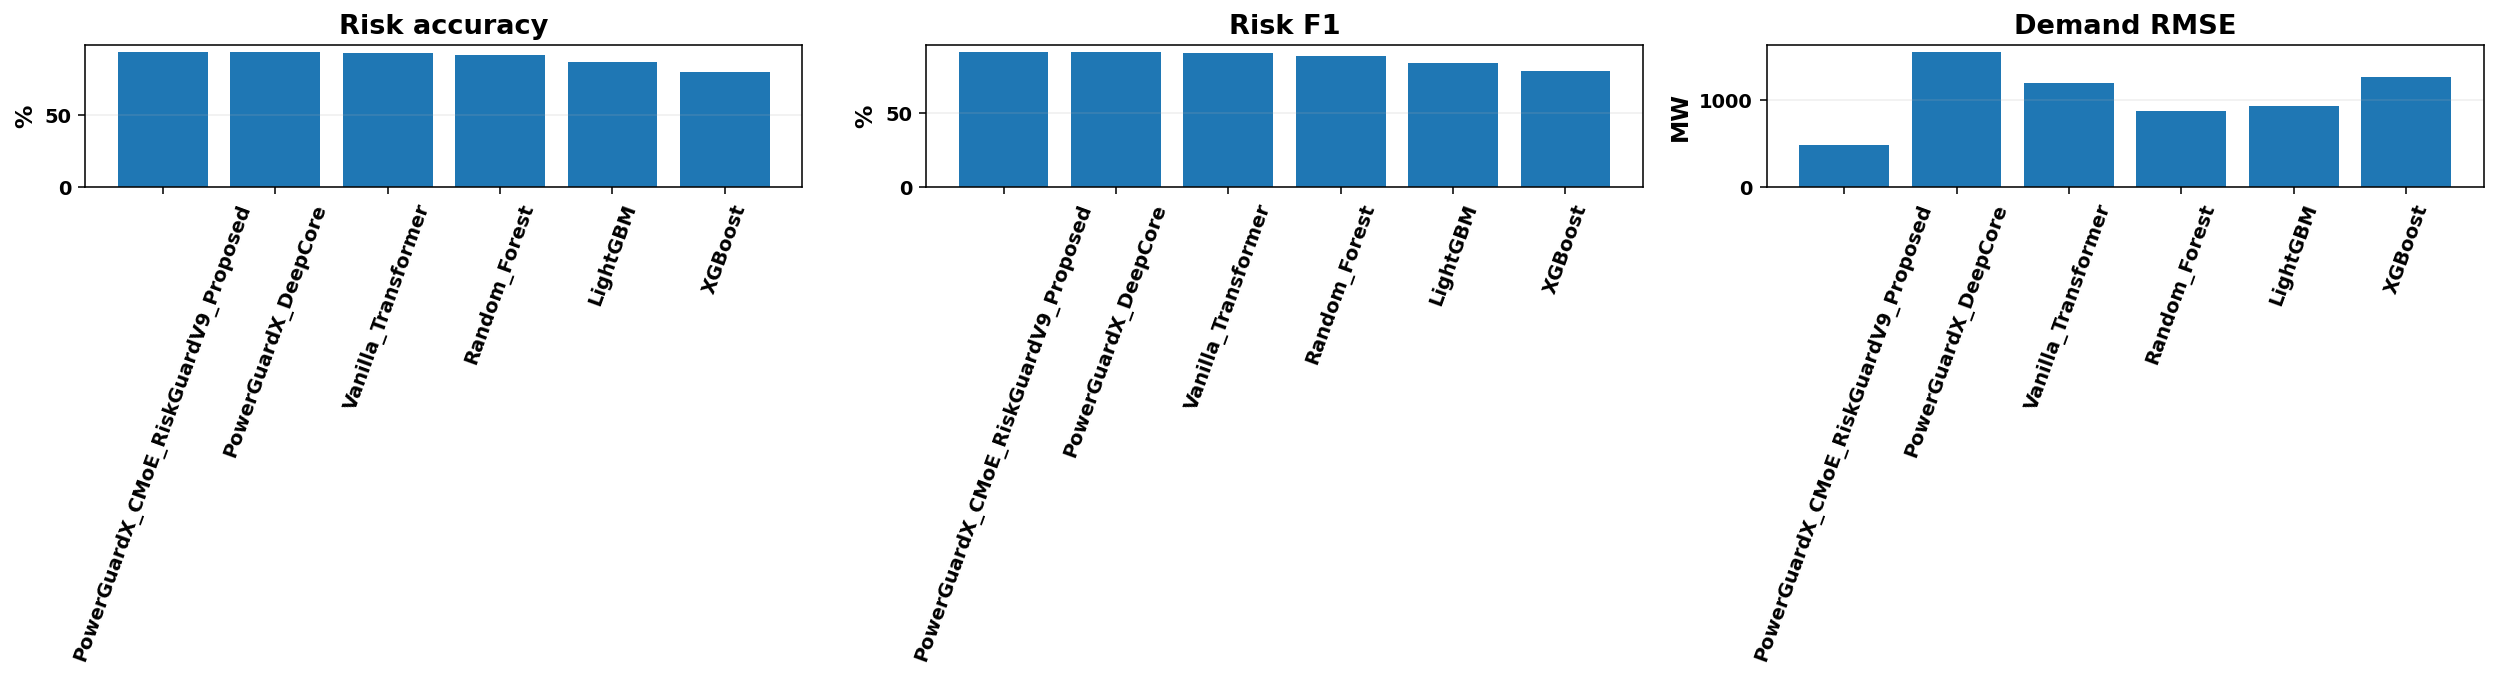

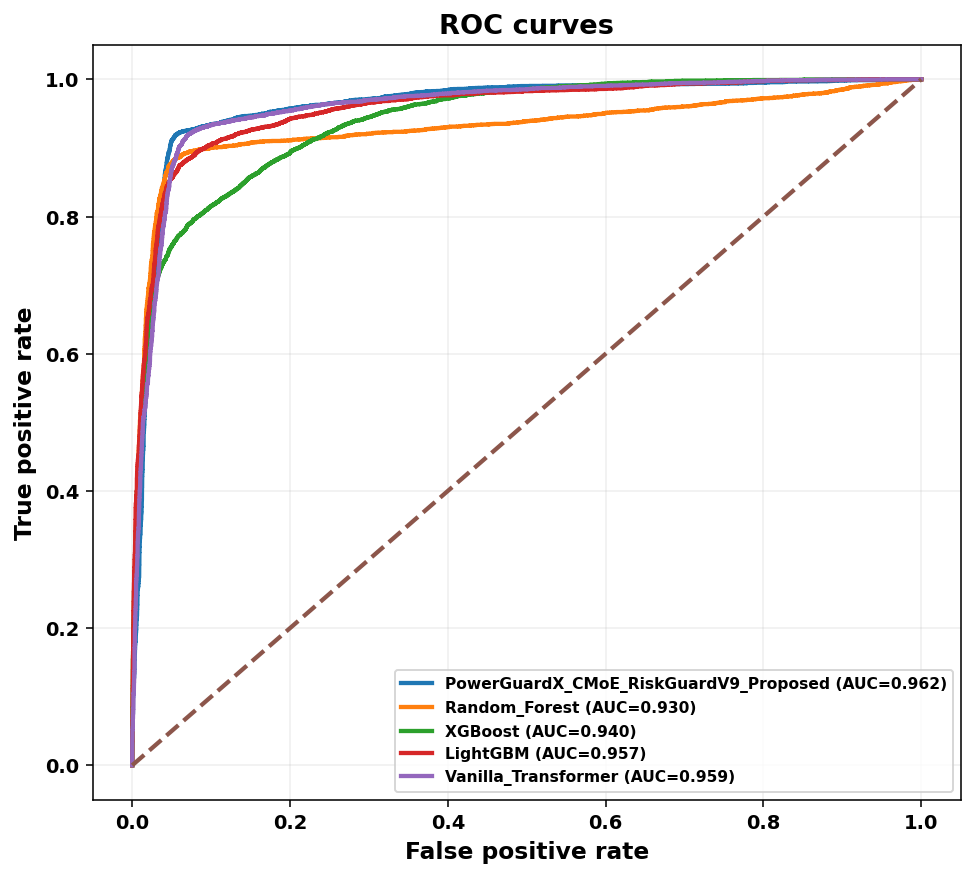

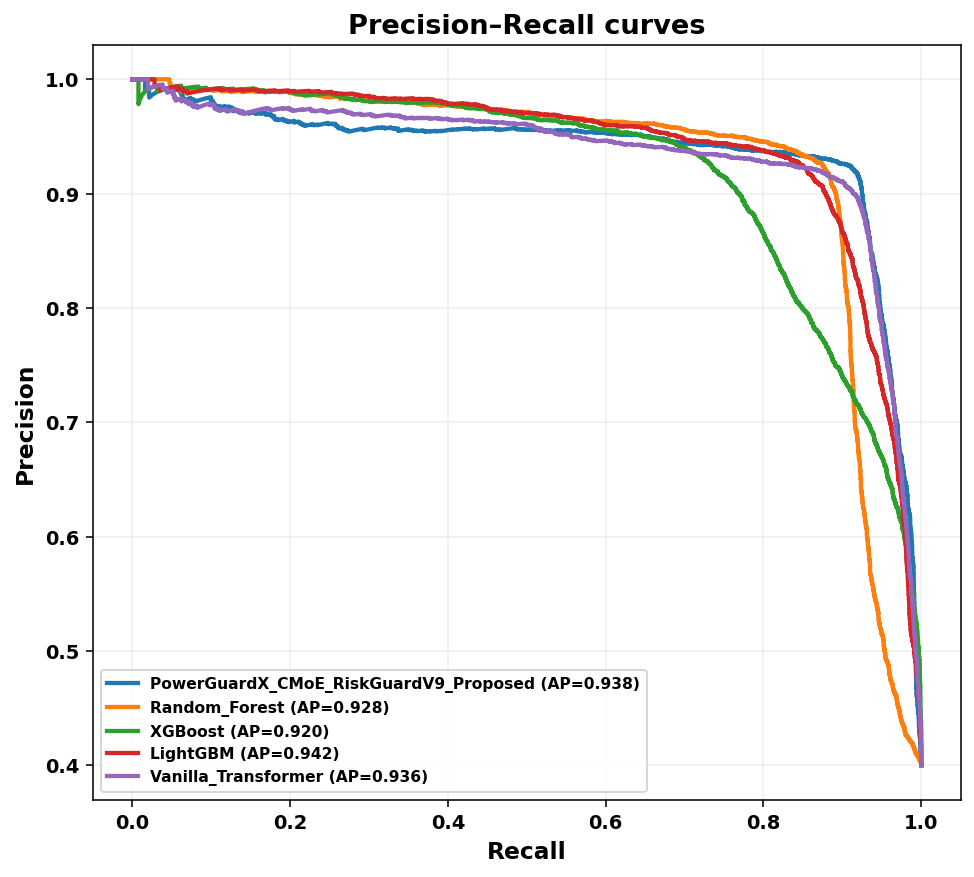

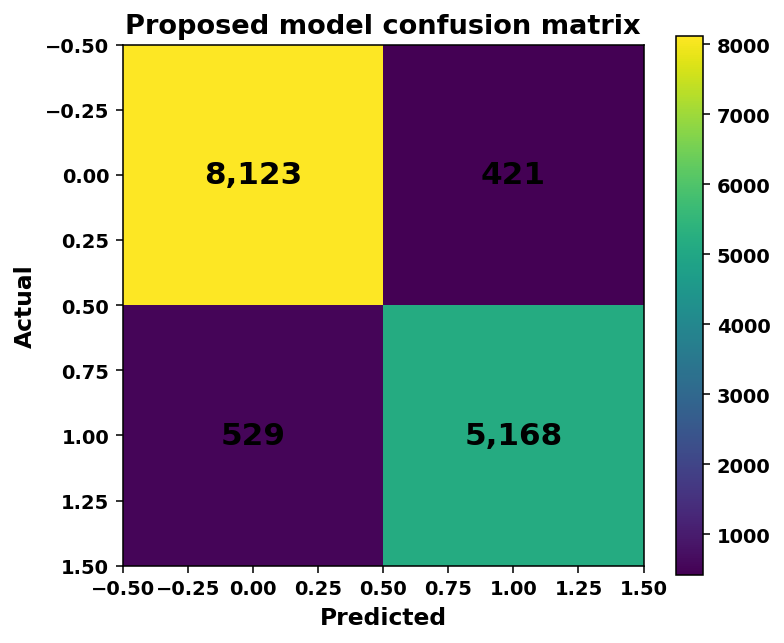

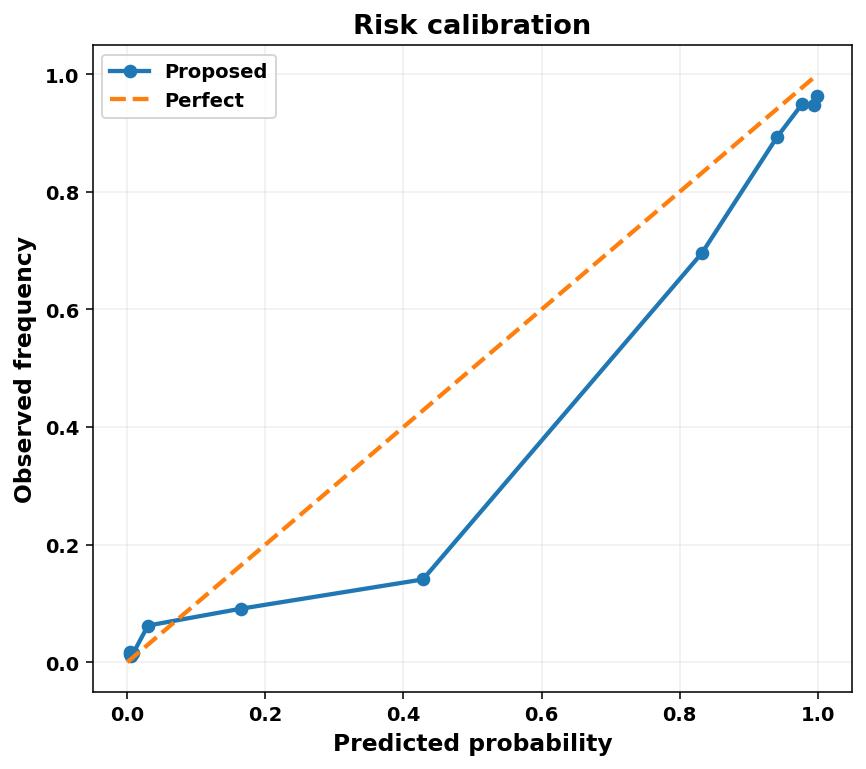

In [20]:
# Collect final + selected strong competitors
pred_registry={'PowerGuardX_CMoE_RiskGuardV9_Proposed':{'test':final_pred,'threshold':thr}}
pred_registry.update({k:v for k,v in classical_preds.items()})
pred_registry.update({('PowerGuardX_DeepCore' if k=='PowerGuardX_Proposed' else k):v for k,v in neural_preds.items() if k!='PowerGuardX_Proposed'})
yt_r=y_r[test_ids].astype(int)

# metric comparison
fig,axes=plt.subplots(1,3,figsize=(18,5))
plotdf=all_metrics.sort_values('Risk_F1',ascending=False)
axes[0].bar(plotdf.Model,plotdf.Risk_Accuracy*100); axes[0].set_title('Risk accuracy'); axes[0].set_ylabel('%')
axes[1].bar(plotdf.Model,plotdf.Risk_F1*100); axes[1].set_title('Risk F1'); axes[1].set_ylabel('%')
axes[2].bar(plotdf.Model,plotdf.Demand_RMSE); axes[2].set_title('Demand RMSE'); axes[2].set_ylabel('MW')
for ax in axes: ax.tick_params(axis='x',rotation=70); ax.grid(axis='y',alpha=.2)
fig.tight_layout(); fig.savefig(FIG_DIR/'Fig_Model_Comparison.png',bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(8,7))
for name,obj in pred_registry.items():
    p=obj['test']['risk_prob']; fpr,tpr,_=roc_curve(yt_r,p); ax.plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(yt_r,p):.3f})')
ax.plot([0,1],[0,1],'--'); ax.set_title('ROC curves'); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.savefig(FIG_DIR/'Fig_ROC_All_Models.png',bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(8,7))
for name,obj in pred_registry.items():
    p=obj['test']['risk_prob']; pre,rec,_=precision_recall_curve(yt_r,p); ax.plot(rec,pre,label=f'{name} (AP={average_precision_score(yt_r,p):.3f})')
ax.set_title('Precision–Recall curves'); ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.savefig(FIG_DIR/'Fig_PR_All_Models.png',bbox_inches='tight'); plt.show()

p=final_pred['risk_prob']; q=(p>=thr).astype(int); cm=confusion_matrix(yt_r,q)
fig,ax=plt.subplots(figsize=(6,5)); im=ax.imshow(cm); ax.set_title('Proposed model confusion matrix'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
for i in range(2):
 for j in range(2): ax.text(j,i,f'{cm[i,j]:,}',ha='center',va='center',fontsize=16,fontweight='bold')
fig.colorbar(im,ax=ax); fig.savefig(FIG_DIR/'Fig_Confusion_Proposed.png',bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(7,6)); frac,mean=calibration_curve(yt_r,p,n_bins=12,strategy='quantile'); ax.plot(mean,frac,marker='o',label='Proposed'); ax.plot([0,1],[0,1],'--',label='Perfect')
ax.set_title('Risk calibration'); ax.set_xlabel('Predicted probability'); ax.set_ylabel('Observed frequency'); ax.legend(); ax.grid(alpha=.2)
fig.savefig(FIG_DIR/'Fig_Calibration_Proposed.png',bbox_inches='tight'); plt.show()

## 18. Demand and deficit diagnostic curves

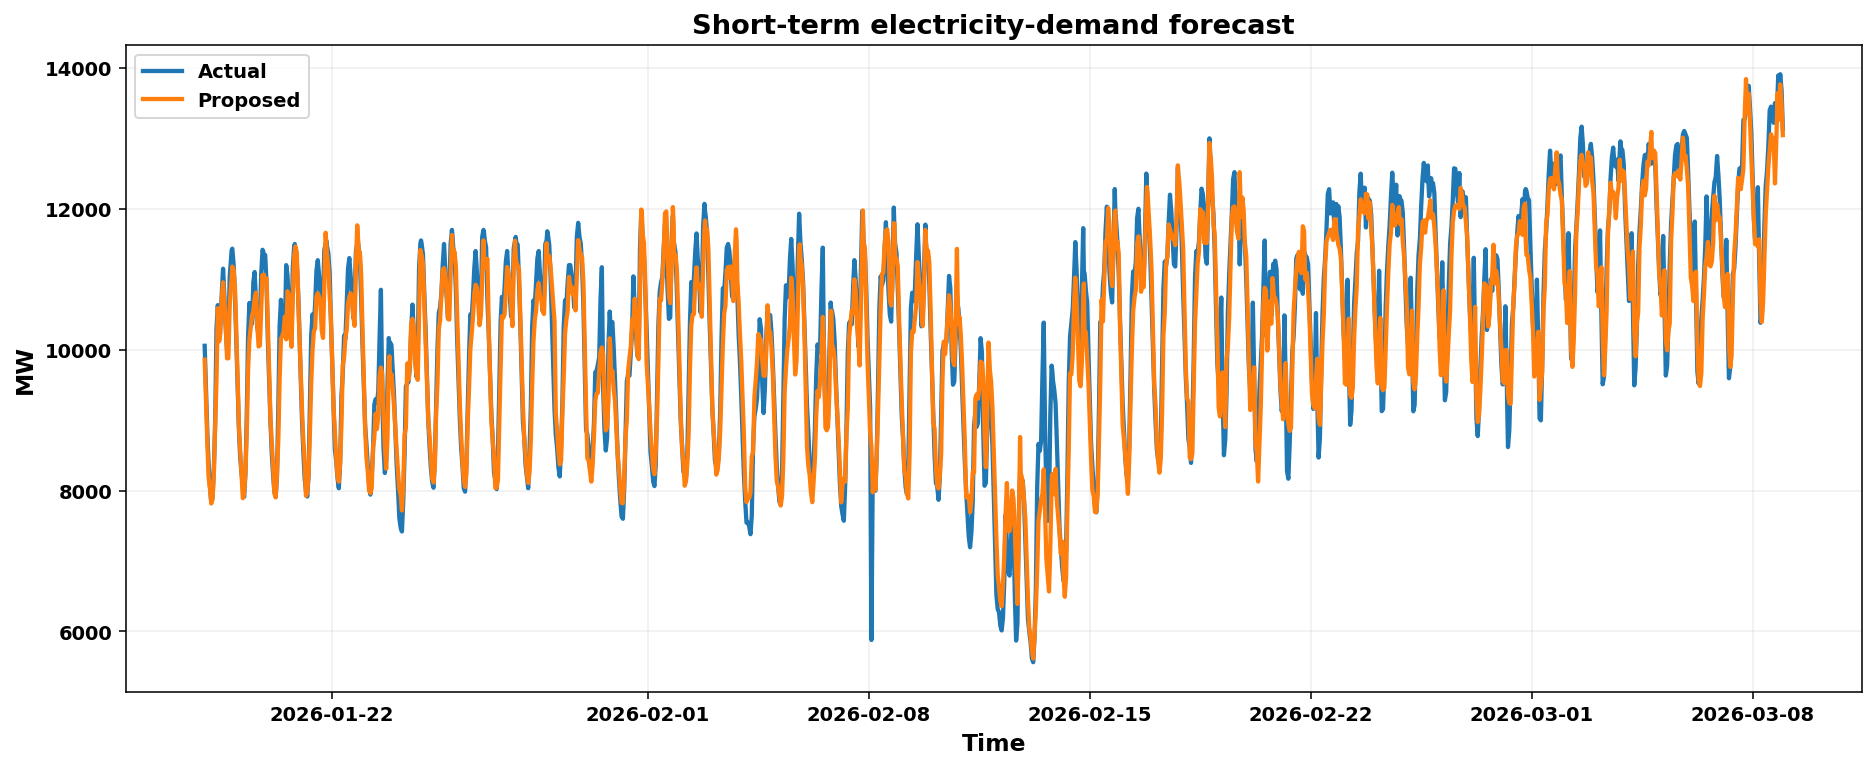

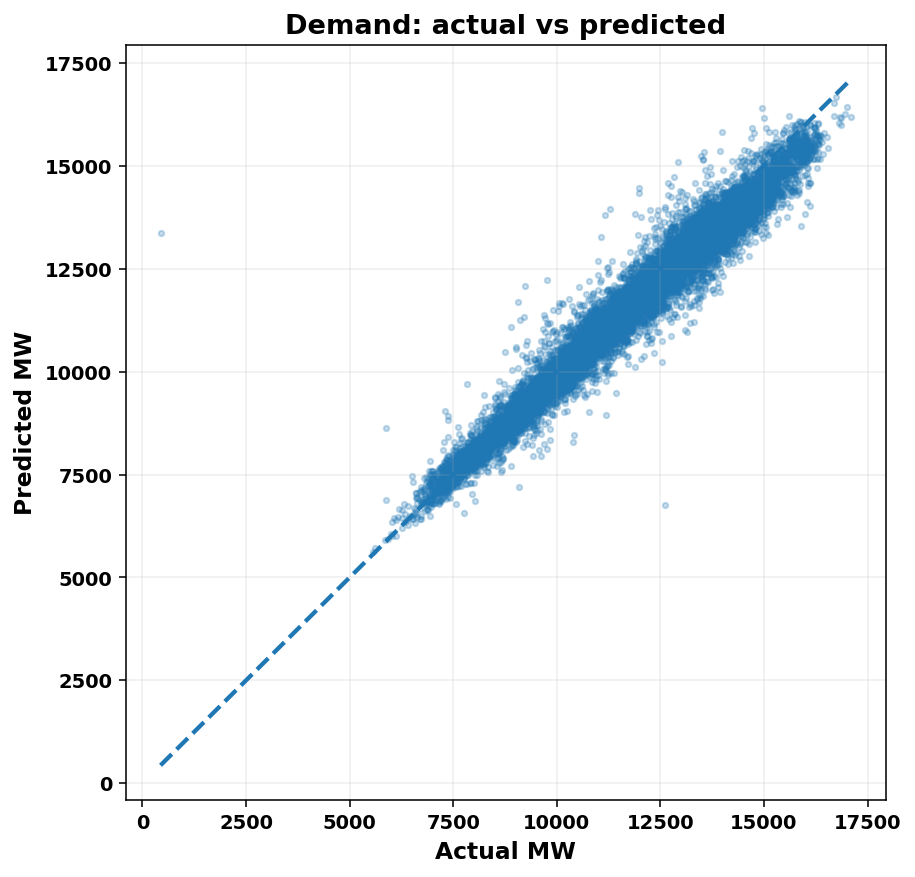

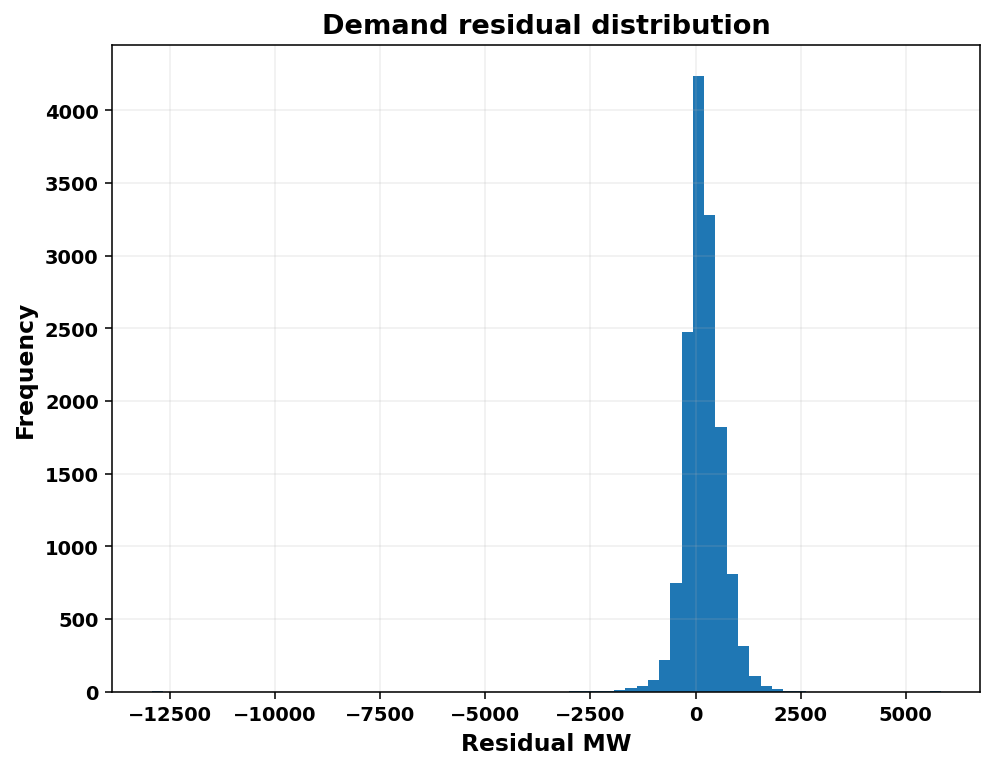

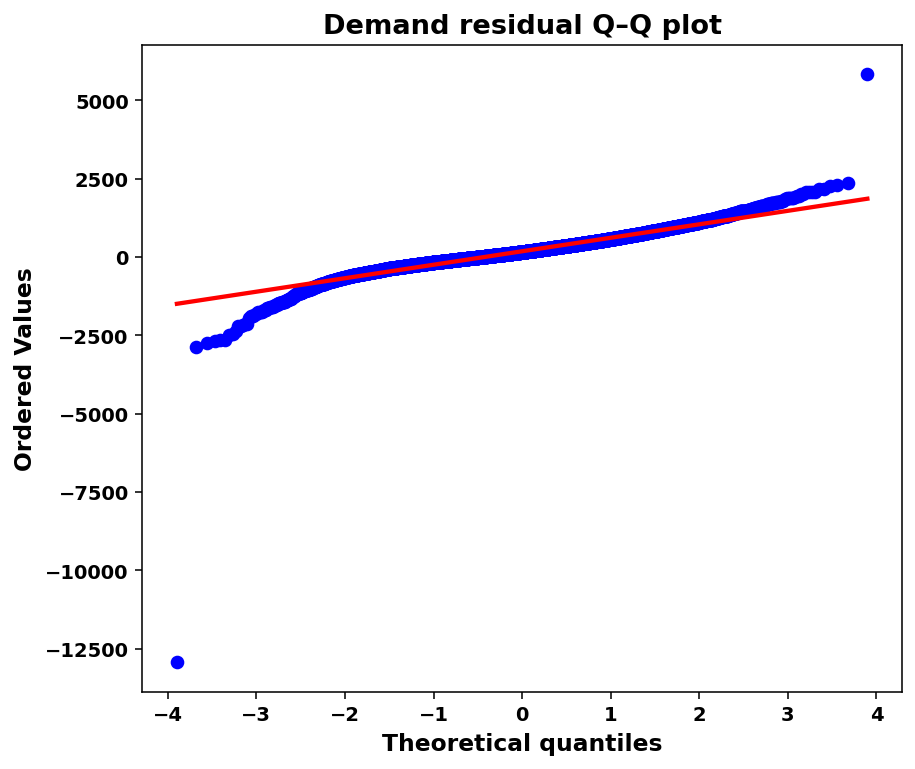

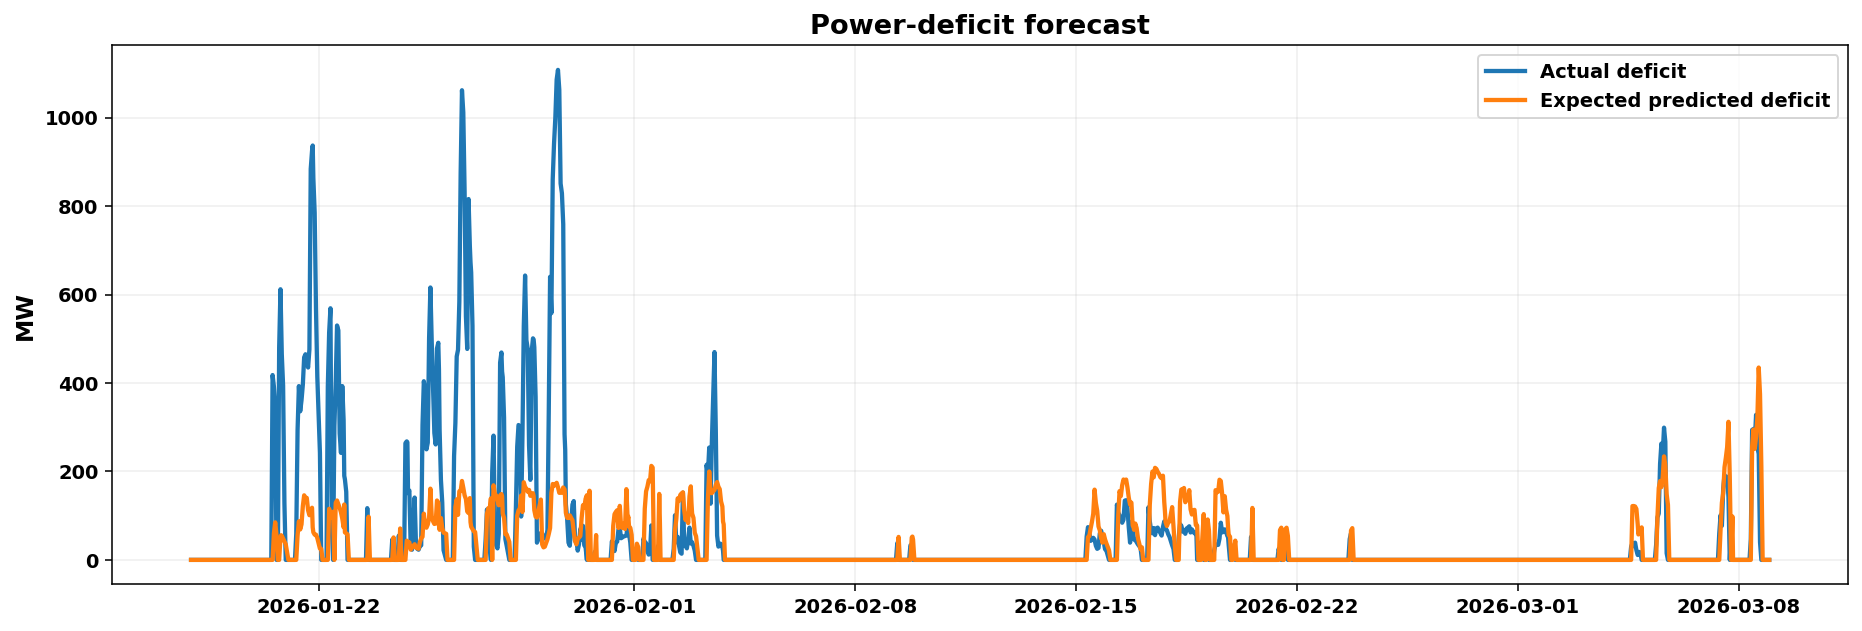

In [21]:
ids=test_ids; td=y_d[ids]; pdm=final_pred['demand']; tf=raw_def[ids]; pdf=final_pred['deficit_expected']; dt=M.datetime.iloc[ids]

fig,ax=plt.subplots(figsize=(16,6)); n=min(1200,len(ids)); ax.plot(dt.iloc[-n:],td[-n:],label='Actual'); ax.plot(dt.iloc[-n:],pdm[-n:],label='Proposed')
ax.set_title('Short-term electricity-demand forecast'); ax.set_xlabel('Time'); ax.set_ylabel('MW'); ax.legend(); ax.grid(alpha=.2)
fig.savefig(FIG_DIR/'Fig_Demand_Timeseries.png',bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(7,7)); ax.scatter(td,pdm,s=8,alpha=.25); lo=min(td.min(),pdm.min()); hi=max(td.max(),pdm.max()); ax.plot([lo,hi],[lo,hi],'--'); ax.set_title('Demand: actual vs predicted'); ax.set_xlabel('Actual MW'); ax.set_ylabel('Predicted MW'); ax.grid(alpha=.2)
fig.savefig(FIG_DIR/'Fig_Demand_Actual_Predicted.png',bbox_inches='tight'); plt.show()

res=td-pdm
fig,ax=plt.subplots(figsize=(8,6)); ax.hist(res,bins=70); ax.set_title('Demand residual distribution'); ax.set_xlabel('Residual MW'); ax.set_ylabel('Frequency'); ax.grid(alpha=.2)
fig.savefig(FIG_DIR/'Fig_Demand_Residuals.png',bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(7,6)); stats.probplot(res,dist='norm',plot=ax); ax.set_title('Demand residual Q–Q plot'); fig.savefig(FIG_DIR/'Fig_Demand_QQ.png',bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(16,5)); ax.plot(dt.iloc[-n:],tf[-n:],label='Actual deficit'); ax.plot(dt.iloc[-n:],pdf[-n:],label='Expected predicted deficit'); ax.set_title('Power-deficit forecast'); ax.set_ylabel('MW'); ax.legend(); ax.grid(alpha=.2)
fig.savefig(FIG_DIR/'Fig_Deficit_Timeseries.png',bbox_inches='tight'); plt.show()

## 19. Proposed model explainability — lag attention and variable gates

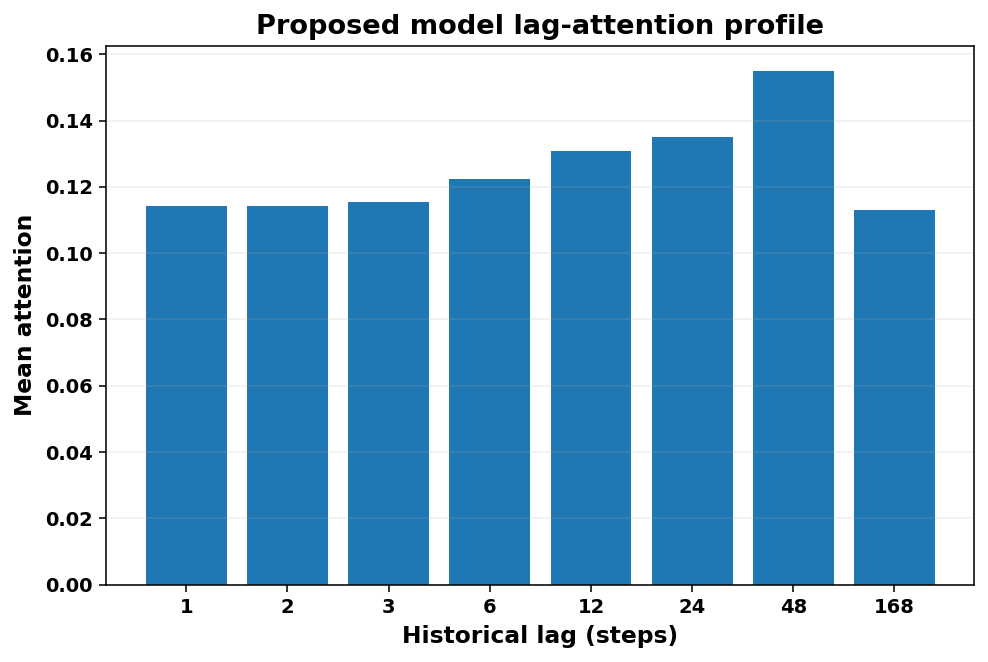

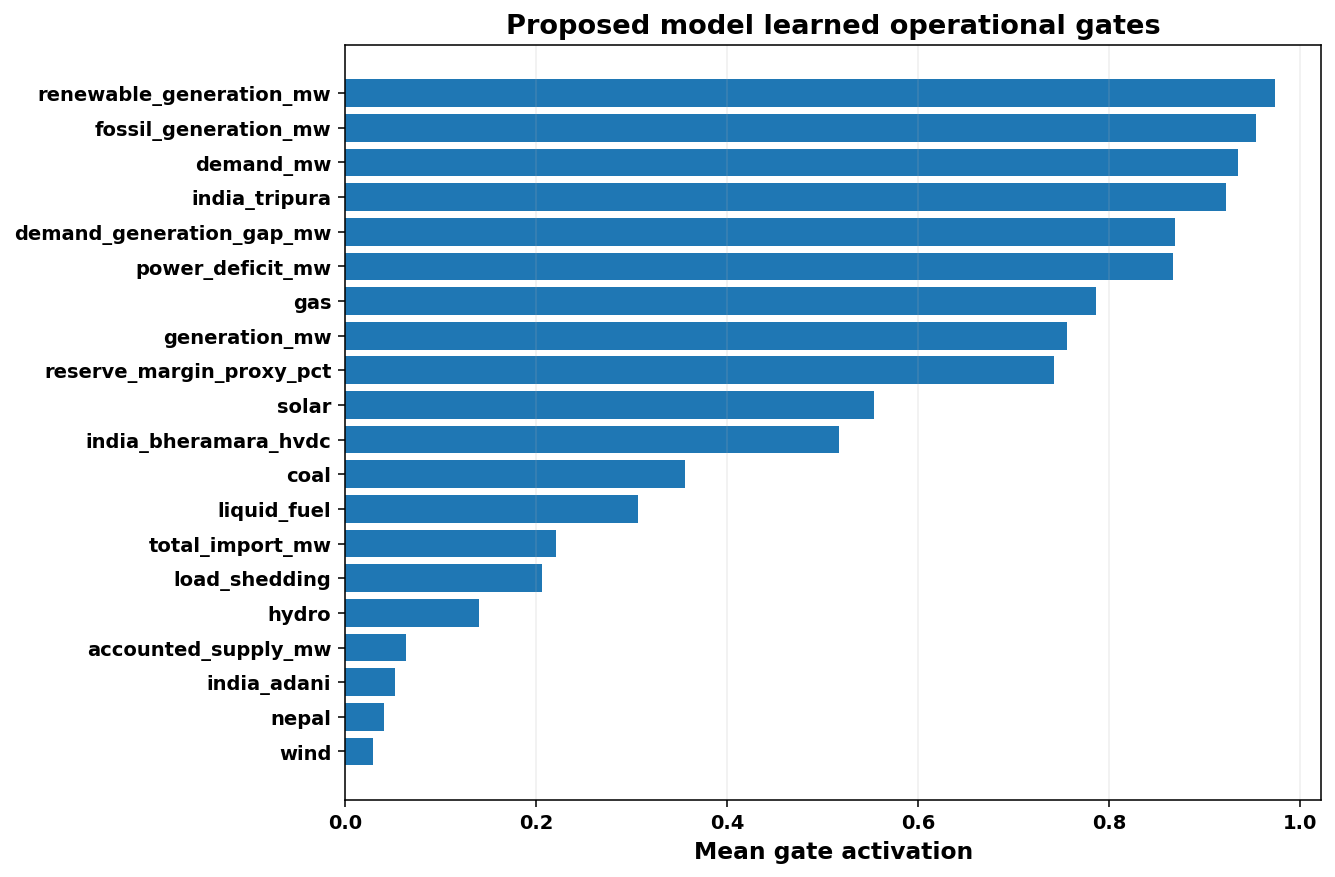

In [22]:
model=trained['PowerGuardX_Proposed']; model.eval();
h,e,yd,yr,ym,ip,w,j=next(iter(te_loader)); h,e=h.to(DEVICE),e.to(DEVICE)
with torch.no_grad(): d,r,m,a,g=model(h,e,return_aux=True)
att=a.mean(0).cpu().numpy(); gate=g.mean((0,1)).cpu().numpy()
fig,ax=plt.subplots(figsize=(8,5)); ax.bar([str(x) for x in LAGS],att); ax.set_title('Proposed model lag-attention profile'); ax.set_xlabel('Historical lag (steps)'); ax.set_ylabel('Mean attention'); ax.grid(axis='y',alpha=.2)
fig.savefig(FIG_DIR/'Fig_Proposed_Lag_Attention.png',bbox_inches='tight'); plt.show()

order=np.argsort(gate)[::-1][:20]
fig,ax=plt.subplots(figsize=(9,7)); ax.barh(np.array(operational)[order][::-1],gate[order][::-1]); ax.set_title('Proposed model learned operational gates'); ax.set_xlabel('Mean gate activation'); ax.grid(axis='x',alpha=.2)
fig.savefig(FIG_DIR/'Fig_Proposed_Feature_Gates.png',bbox_inches='tight'); plt.show()

## 20. SHAP for the strongest tree baseline

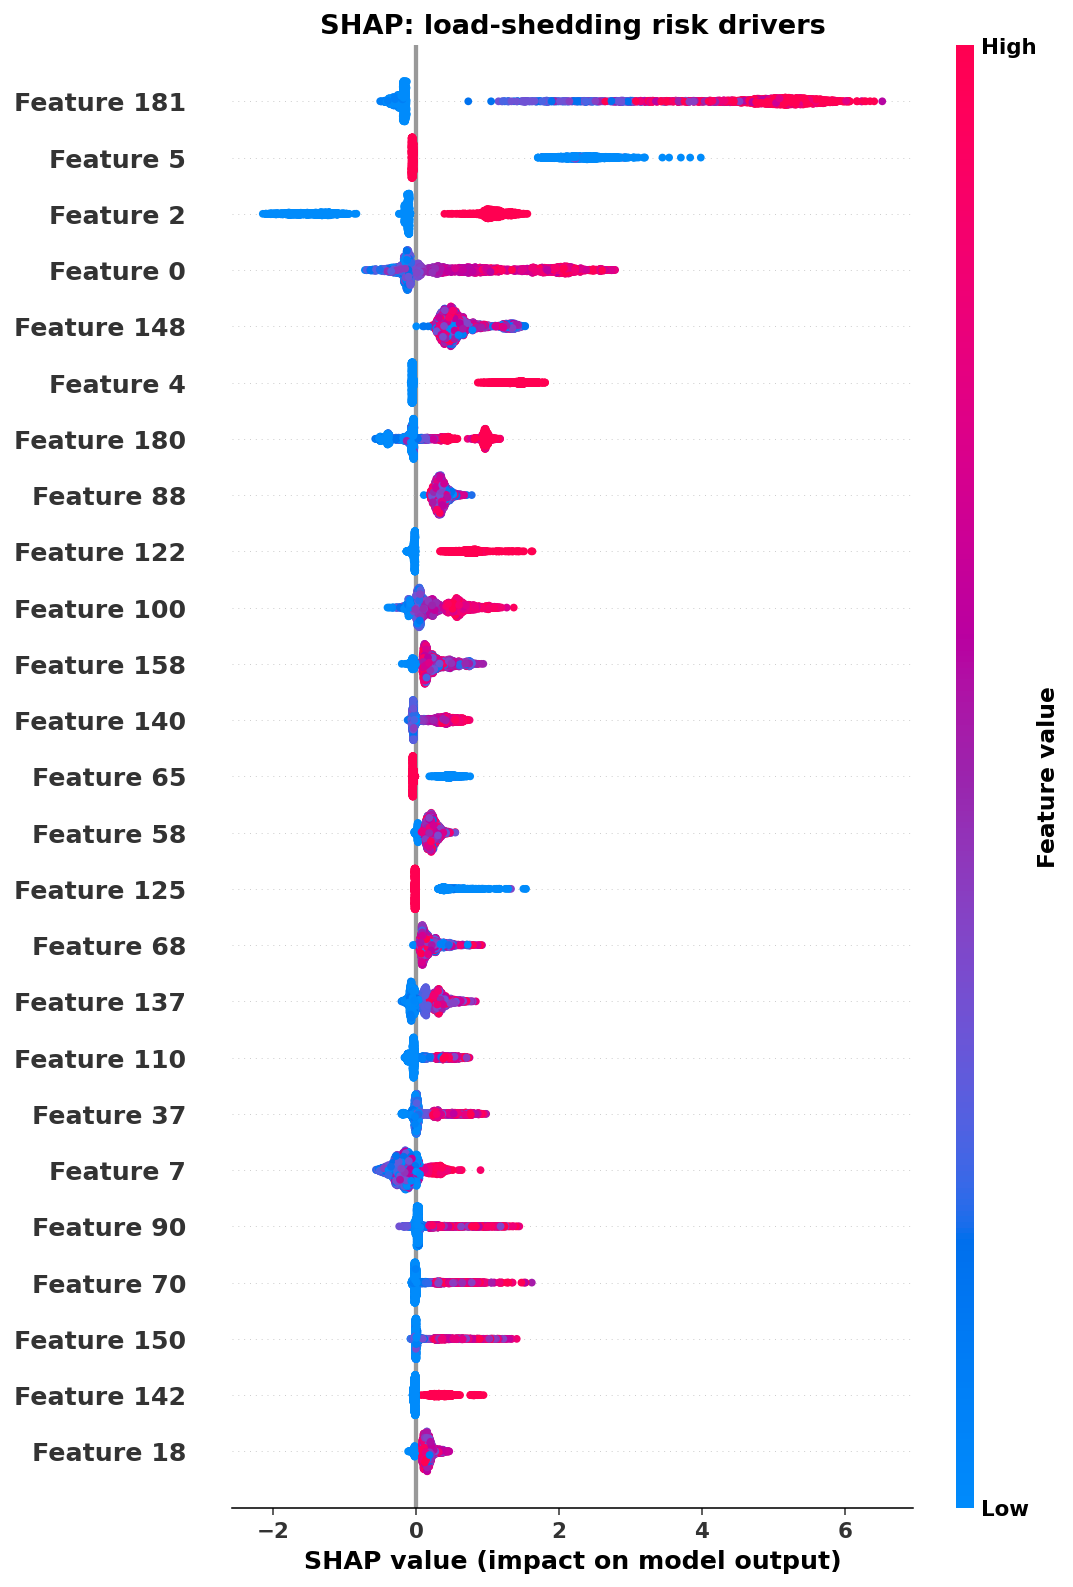

In [23]:
try:
 import shap
 if 'LightGBM' in fitted:
    md,mc,mm=fitted['LightGBM']; sample=np.random.default_rng(SEED).choice(len(Xte),size=min(2500,len(Xte)),replace=False); Xs=Xte[sample]
    expl=shap.TreeExplainer(mc); sv=expl.shap_values(Xs)
    if isinstance(sv,list): sv=sv[-1]
    shap.summary_plot(sv,Xs,max_display=25,show=False); plt.title('SHAP: load-shedding risk drivers'); plt.tight_layout(); plt.savefig(FIG_DIR/'Fig_SHAP_Risk_LightGBM.png',dpi=600,bbox_inches='tight'); plt.show()
except Exception as e: print('SHAP skipped:',e)

## 21. Ablation study — fuel mix, weather, persistence inputs

In [24]:
# Inference ablation on the deep proposed component; no retraining, so it measures reliance on each information group.
@torch.no_grad()
def ablated_predict(zero_fuel=False,zero_weather=False,zero_persistence=False):
    model=trained['PowerGuardX_Proposed']; model.eval(); ids=[]; dz=[]; rp=[]; mz=[]
    for h,e,yd,yr,ym,ip,w,j in te_loader:
        h=h.to(DEVICE).clone(); e=e.to(DEVICE).clone()
        if zero_fuel and fuel_idx: h[:,:,fuel_idx]=0
        if zero_weather and weather_exo_idx: e[:,weather_exo_idx]=0
        if zero_persistence:
            for nm in ['prev_risk','prev_deficit','risk_run_6','risk_run_24']:
                if nm in exo_names: e[:,exo_names.index(nm)]=0
        d,r,m=model(h,e); ids.extend(j.numpy()); dz.extend(d.cpu().numpy()); rp.extend(torch.sigmoid(r).cpu().numpy()); mz.extend(m.cpu().numpy())
    ids=np.asarray(ids); rp=np.asarray(rp); mag=inv_mag(np.asarray(mz)); return ids,inv_demand(np.asarray(dz),ids),rp,rp*mag

abl=[]
for label,kw in [('Full',{}),('No fuel',{'zero_fuel':True}),('No weather',{'zero_weather':True}),('No persistence',{'zero_persistence':True})]:
    ids,dd,pp,ff=ablated_predict(**kw); th0=neural_preds['PowerGuardX_Proposed']['threshold']; row={'Setting':label}; row.update(reg_metrics(y_d[ids],dd,'Demand')); row.update(cls_metrics(y_r[ids].astype(int),pp,th0)); row.update(reg_metrics(raw_def[ids],ff,'Deficit')); abl.append(row)
ablation=pd.DataFrame(abl); display(ablation); ablation.to_csv(TABLE_DIR/'ablation_v4.csv',index=False)

,Setting,Demand_MAE,Demand_RMSE,Demand_MAPE_pct,Demand_R2,Risk_Threshold,Risk_Accuracy,Risk_BalancedAcc,Risk_Precision,Risk_Recall,Risk_F1,Risk_ROC_AUC,Risk_PR_AUC,Risk_Brier,Deficit_MAE,Deficit_RMSE,Deficit_MAPE_pct,Deficit_R2
0,Full,1234.405656,1556.550522,11.965662,0.510222,0.82,0.933291,0.928935,0.924673,0.907144,0.915825,0.961545,0.937520,0.069570,171.030733,419.406363,2913.084748,-1.592155
1,No fuel,494.860920,716.947256,4.448766,0.896092,0.82,0.925497,0.917877,0.930215,0.879761,0.904285,0.968425,0.953217,0.062218,127.780983,240.638752,2918.257634,0.146660
2,No weather,1249.875745,1586.179257,12.148292,0.491399,0.82,0.933783,0.929812,0.923406,0.909953,0.916630,0.961360,0.936251,0.073347,176.126163,421.971476,3274.876590,-1.623959
3,No persistence,1825.911598,2030.619679,16.629922,0.166453,0.82,0.641247,0.551840,0.986755,0.104616,0.189176,0.879412,0.862197,0.277343,99.524046,274.050199,884.695639,-0.106754


## 22. Statistical analysis — 95% bootstrap CIs, paired tests, residual diagnostics

In [25]:
rng=np.random.default_rng(SEED)
def bootstrap_ci(y,p,func,B=1000):
    vals=[]; n=len(y)
    for _ in range(B):
        ii=rng.integers(0,n,n); vals.append(func(y[ii],p[ii]))
    return np.percentile(vals,[2.5,50,97.5])

ci_rows=[]
for _,r in all_metrics.iterrows():
    name=r.Model
    if name=='PowerGuardX_CMoE_RiskGuardV9_Proposed': obj={'test':final_pred,'threshold':thr}
    elif name in classical_preds: obj=classical_preds[name]
    elif name=='PowerGuardX_DeepCore': obj=neural_preds['PowerGuardX_Proposed']
    elif name in neural_preds: obj=neural_preds[name]
    else: continue
    p=obj['test']; t=obj['threshold']; ids=p['idx'];
    ci_rows.append({'Model':name,
      'Demand_MAE_CI95':bootstrap_ci(y_d[ids],p['demand'],mean_absolute_error).tolist(),
      'Risk_Accuracy_CI95':bootstrap_ci(y_r[ids].astype(int),(p['risk_prob']>=t).astype(int),accuracy_score).tolist(),
      'Risk_F1_CI95':bootstrap_ci(y_r[ids].astype(int),(p['risk_prob']>=t).astype(int),lambda a,b:f1_score(a,b,zero_division=0)).tolist(),
      'Deficit_MAE_CI95':bootstrap_ci(raw_def[ids],p['deficit_expected'],mean_absolute_error).tolist()})
ci=pd.DataFrame(ci_rows); display(ci); ci.to_csv(TABLE_DIR/'bootstrap_95CI.csv',index=False)

# Paired tests: proposed vs every comparator on the exact same test timestamps.
def dm_like(e1,e2):
    d=e1**2-e2**2; stat=d.mean()/(d.std(ddof=1)/np.sqrt(len(d))+1e-12); p=2*stats.t.sf(abs(stat),df=max(1,len(d)-1)); return stat,p
stat_rows=[]; prop=final_pred
for name,obj in pred_registry.items():
    if name=='PowerGuardX_CMoE_RiskGuardV9_Proposed': continue
    q=obj['test']; ids=q['idx'];
    # same test ids by construction
    dm,pdm=dm_like(y_d[ids]-prop['demand'],y_d[ids]-q['demand'])
    yp=(prop['risk_prob']>=thr).astype(int); yc=(q['risk_prob']>=obj['threshold']).astype(int); yt=y_r[ids].astype(int)
    b=np.sum((yp==yt)&(yc!=yt)); c=np.sum((yp!=yt)&(yc==yt)); mc=(abs(b-c)-1)**2/max(b+c,1); pmc=stats.chi2.sf(mc,1)
    try: wz,pw=stats.wilcoxon(np.abs(raw_def[ids]-prop['deficit_expected']),np.abs(raw_def[ids]-q['deficit_expected']))
    except: wz,pw=np.nan,np.nan
    stat_rows.append({'Comparator':name,'DM_stat':dm,'DM_p':pdm,'McNemar_chi2':mc,'McNemar_p':pmc,'Wilcoxon_deficit':wz,'Wilcoxon_p':pw})
stats_table=pd.DataFrame(stat_rows); display(stats_table); stats_table.to_csv(TABLE_DIR/'paired_statistical_tests.csv',index=False)

# residual diagnostics
res=y_d[test_ids]-final_pred['demand']
print('Residual mean:',res.mean(),'std:',res.std())
print('Shapiro on 5000-sample:',stats.shapiro(res[:min(5000,len(res))]))
try:
 from statsmodels.stats.diagnostic import acorr_ljungbox
 display(acorr_ljungbox(res,lags=[12,24,48],return_df=True))
except Exception as e: print('Ljung-Box skipped:',e)

,Model,Demand_MAE_CI95,Risk_Accuracy_CI95,Risk_F1_CI95,Deficit_MAE_CI95
0,PowerGuardX_CMoE_RiskGuardV9_Proposed,"[345.01398797841756, 350.5117203799863, 356.09...","[0.9293588933361421, 0.9333614212485078, 0.937...","[0.9104326959024973, 0.9158065547351006, 0.921...","[69.10819488216714, 72.14278521572209, 75.3042..."
1,PowerGuardX_DeepCore,"[1219.4257966871808, 1234.0821424712294, 1248....","[0.9292184537602697, 0.9331507618846991, 0.937...","[0.9106684597493074, 0.9160015924296288, 0.921...","[164.70803514105043, 171.00311564408156, 177.3..."
2,Vanilla_Transformer,"[881.8344984859913, 893.4830038146813, 907.323...","[0.92008812583386, 0.9244435081806053, 0.92886...","[0.8992385549839705, 0.9050685774553341, 0.910...","[466.4932794130749, 485.75387647024013, 507.22..."
3,Random_Forest,"[600.1396112125203, 609.6999459481359, 620.238...","[0.905062846710203, 0.9099782318657398, 0.9146...","[0.8823016051177508, 0.8885156910302663, 0.894...","[107.07885216237912, 109.96356327600408, 113.5..."
4,LightGBM,"[680.9134577021549, 690.7505135973071, 701.379...","[0.8552770170634084, 0.8605786110525946, 0.866...","[0.8360752420671302, 0.8432918706967498, 0.850...","[156.26374258607913, 159.94454525831782, 164.4..."
5,XGBoost,"[972.8398889900652, 985.0687866060457, 998.122...","[0.787093602977319, 0.7936240432553894, 0.8000...","[0.7786585150948667, 0.7861928362454011, 0.793...","[132.8442546419264, 136.21968370152774, 140.09..."


,Comparator,DM_stat,DM_p,McNemar_chi2,McNemar_p,Wilcoxon_deficit,Wilcoxon_p
0,Random_Forest,-33.712380,8.938723e-240,201.293900,1.090130e-45,20034485.0,0.0
1,XGBoost,-61.685186,0.000000e+00,1434.299167,0.000000e+00,15780716.0,0.0
2,LightGBM,-57.927469,0.000000e+00,680.557607,5.054349e-150,14285077.0,0.0
3,Vanilla_Transformer,-54.213352,0.000000e+00,40.785146,1.699198e-10,14414485.0,0.0


Residual mean: 186.37169144707187 std: 448.3596178740341
Shapiro on 5000-sample: ShapiroResult(statistic=0.7789638815400833, pvalue=1.7124535734004554e-63)


,lb_stat,lb_pvalue
12,17575.171945,0.0
24,20630.628683,0.0
48,23491.897034,0.0


## 23. Robustness by year, season, and peak period

In [26]:
T=df.loc[base_idx[test_ids],['datetime']].copy().reset_index(drop=True)
T['year']=T.datetime.dt.year
T['month']=T.datetime.dt.month
T['season']=pd.cut(T.month,[0,2,5,9,12],labels=['Winter','Pre-monsoon','Monsoon','Post-monsoon'],include_lowest=True)
if 'peak_period' in df.columns: T['peak_period']=df.loc[base_idx[test_ids],'peak_period'].astype(str).values
else: T['peak_period']=np.where(T.datetime.dt.hour.between(18,22),'Evening peak','Other')
T['yd']=y_d[test_ids];T['pd']=final_pred['demand'];T['yr']=y_r[test_ids].astype(int);T['pr']=final_pred['risk_prob'];T['yf']=raw_def[test_ids];T['pf']=final_pred['deficit_expected']

def group_eval(g):
 return pd.Series({'n':len(g),'Demand_MAE':mean_absolute_error(g.yd,g.pd),'Demand_RMSE':mean_squared_error(g.yd,g.pd)**.5,
                   'Risk_Accuracy':accuracy_score(g.yr,g.pr>=thr),'Risk_F1':f1_score(g.yr,g.pr>=thr,zero_division=0),'Deficit_MAE':mean_absolute_error(g.yf,g.pf)})
for c in ['year','season','peak_period']:
 tab=T.groupby(c,observed=False).apply(group_eval); display(tab); tab.to_csv(TABLE_DIR/f'robustness_{c}.csv')

,n,Demand_MAE,Demand_RMSE,Risk_Accuracy,Risk_F1,Deficit_MAE
year,,,,,,
2024,3879.0,300.619667,468.999468,0.959526,0.961090,111.300826
2025,8755.0,380.165758,505.546455,0.919018,0.891574,60.978956
2026,1607.0,308.903916,407.355803,0.947729,0.882022,38.363181


,n,Demand_MAE,Demand_RMSE,Risk_Accuracy,Risk_F1,Deficit_MAE
season,,,,,,
Winter,2829.0,263.228844,355.313482,0.920467,0.875346,31.940959
Pre-monsoon,2400.0,435.719129,571.928940,0.914583,0.907782,84.649214
Monsoon,4598.0,442.558449,593.710641,0.928447,0.935755,116.465334
Post-monsoon,4414.0,264.064213,366.997152,0.956729,0.910622,44.909289


,n,Demand_MAE,Demand_RMSE,Risk_Accuracy,Risk_F1,Deficit_MAE
peak_period,,,,,,
Day_Peak,580.0,323.171916,425.295992,0.944828,0.925581,62.020910
Evening_Peak,588.0,479.423993,606.595634,0.911565,0.909722,73.352246
Normal,13073.0,345.867244,481.922970,0.933757,0.915759,72.527579


## 24. Final manuscript-ready summary

In [27]:
prop=final_metrics.iloc[0]
print('='*100)
print('POWERGUARD-BD V9 FINAL TEST SUMMARY')
print('='*100)
print(f"Proposed framework: PowerGuardX-CMoE-RiskGuard V9")
print(f"Demand  -> MAE {prop.Demand_MAE:.2f} MW | RMSE {prop.Demand_RMSE:.2f} MW | R2 {prop.Demand_R2:.4f} | MAPE {prop.Demand_MAPE_pct:.2f}%")
print(f"Risk    -> Accuracy {100*prop.Risk_Accuracy:.2f}% | F1 {100*prop.Risk_F1:.2f}% | ROC-AUC {100*prop.Risk_ROC_AUC:.2f}% | PR-AUC {100*prop.Risk_PR_AUC:.2f}%")
print(f"Deficit -> MAE {prop.Deficit_MAE:.2f} MW | RMSE {prop.Deficit_RMSE:.2f} MW | R2 {prop.Deficit_R2:.4f}")
print('\nSelection recipes are stored in CMoE_RiskGuardV9_validation_selection.json; test labels were not used to choose them.')
print('Champion checks are stored in V9_proposed_champion_checks.csv.')


POWERGUARD-BD V9 FINAL TEST SUMMARY
Proposed framework: PowerGuardX-CMoE-RiskGuard V9
Demand  -> MAE 350.46 MW | RMSE 485.55 MW | R2 0.9523 | MAPE 3.16%
Risk    -> Accuracy 93.33% | F1 91.58% | ROC-AUC 96.15% | PR-AUC 93.75%
Deficit -> MAE 72.13 MW | RMSE 199.17 MW | R2 0.4154

Selection recipes are stored in CMoE_RiskGuardV9_validation_selection.json; test labels were not used to choose them.
Champion checks are stored in V9_proposed_champion_checks.csv.


Loading dataset: E:\P work\journal work-2\Final data.csv
Dataset loaded: (94934, 74)


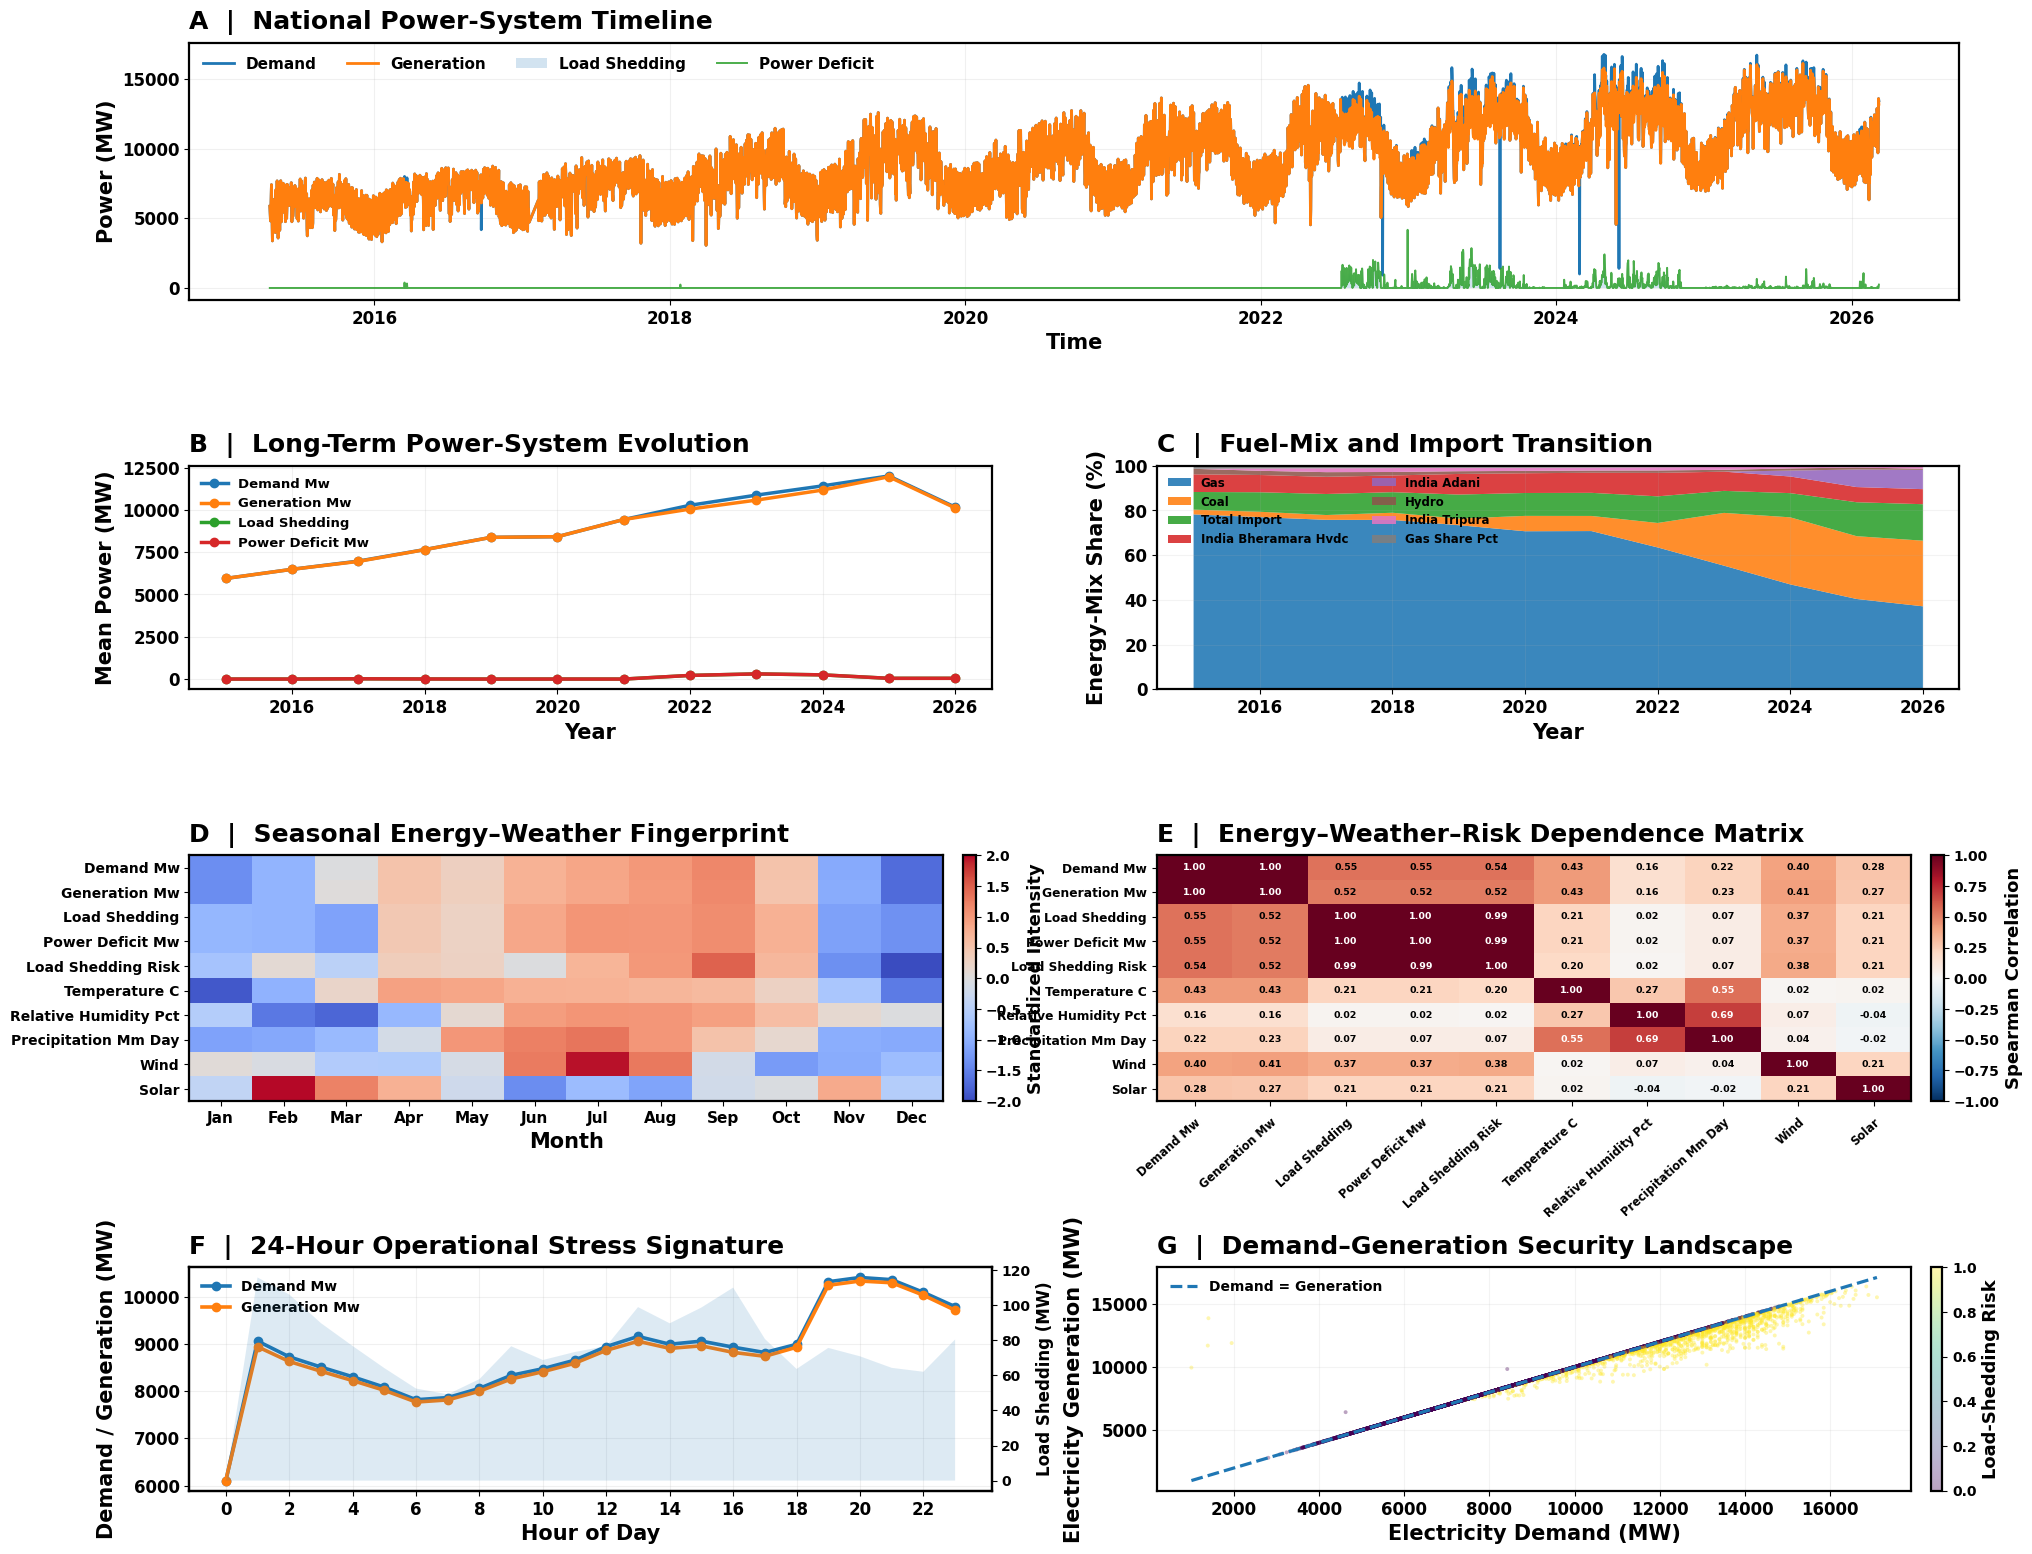


Saved: PowerGuard_BD_Publication_Figures\Fig_PowerGuard_BD_FULL_DATASET_STORY_MAP_FINAL_600DPI.png
File size: 3.70 MB


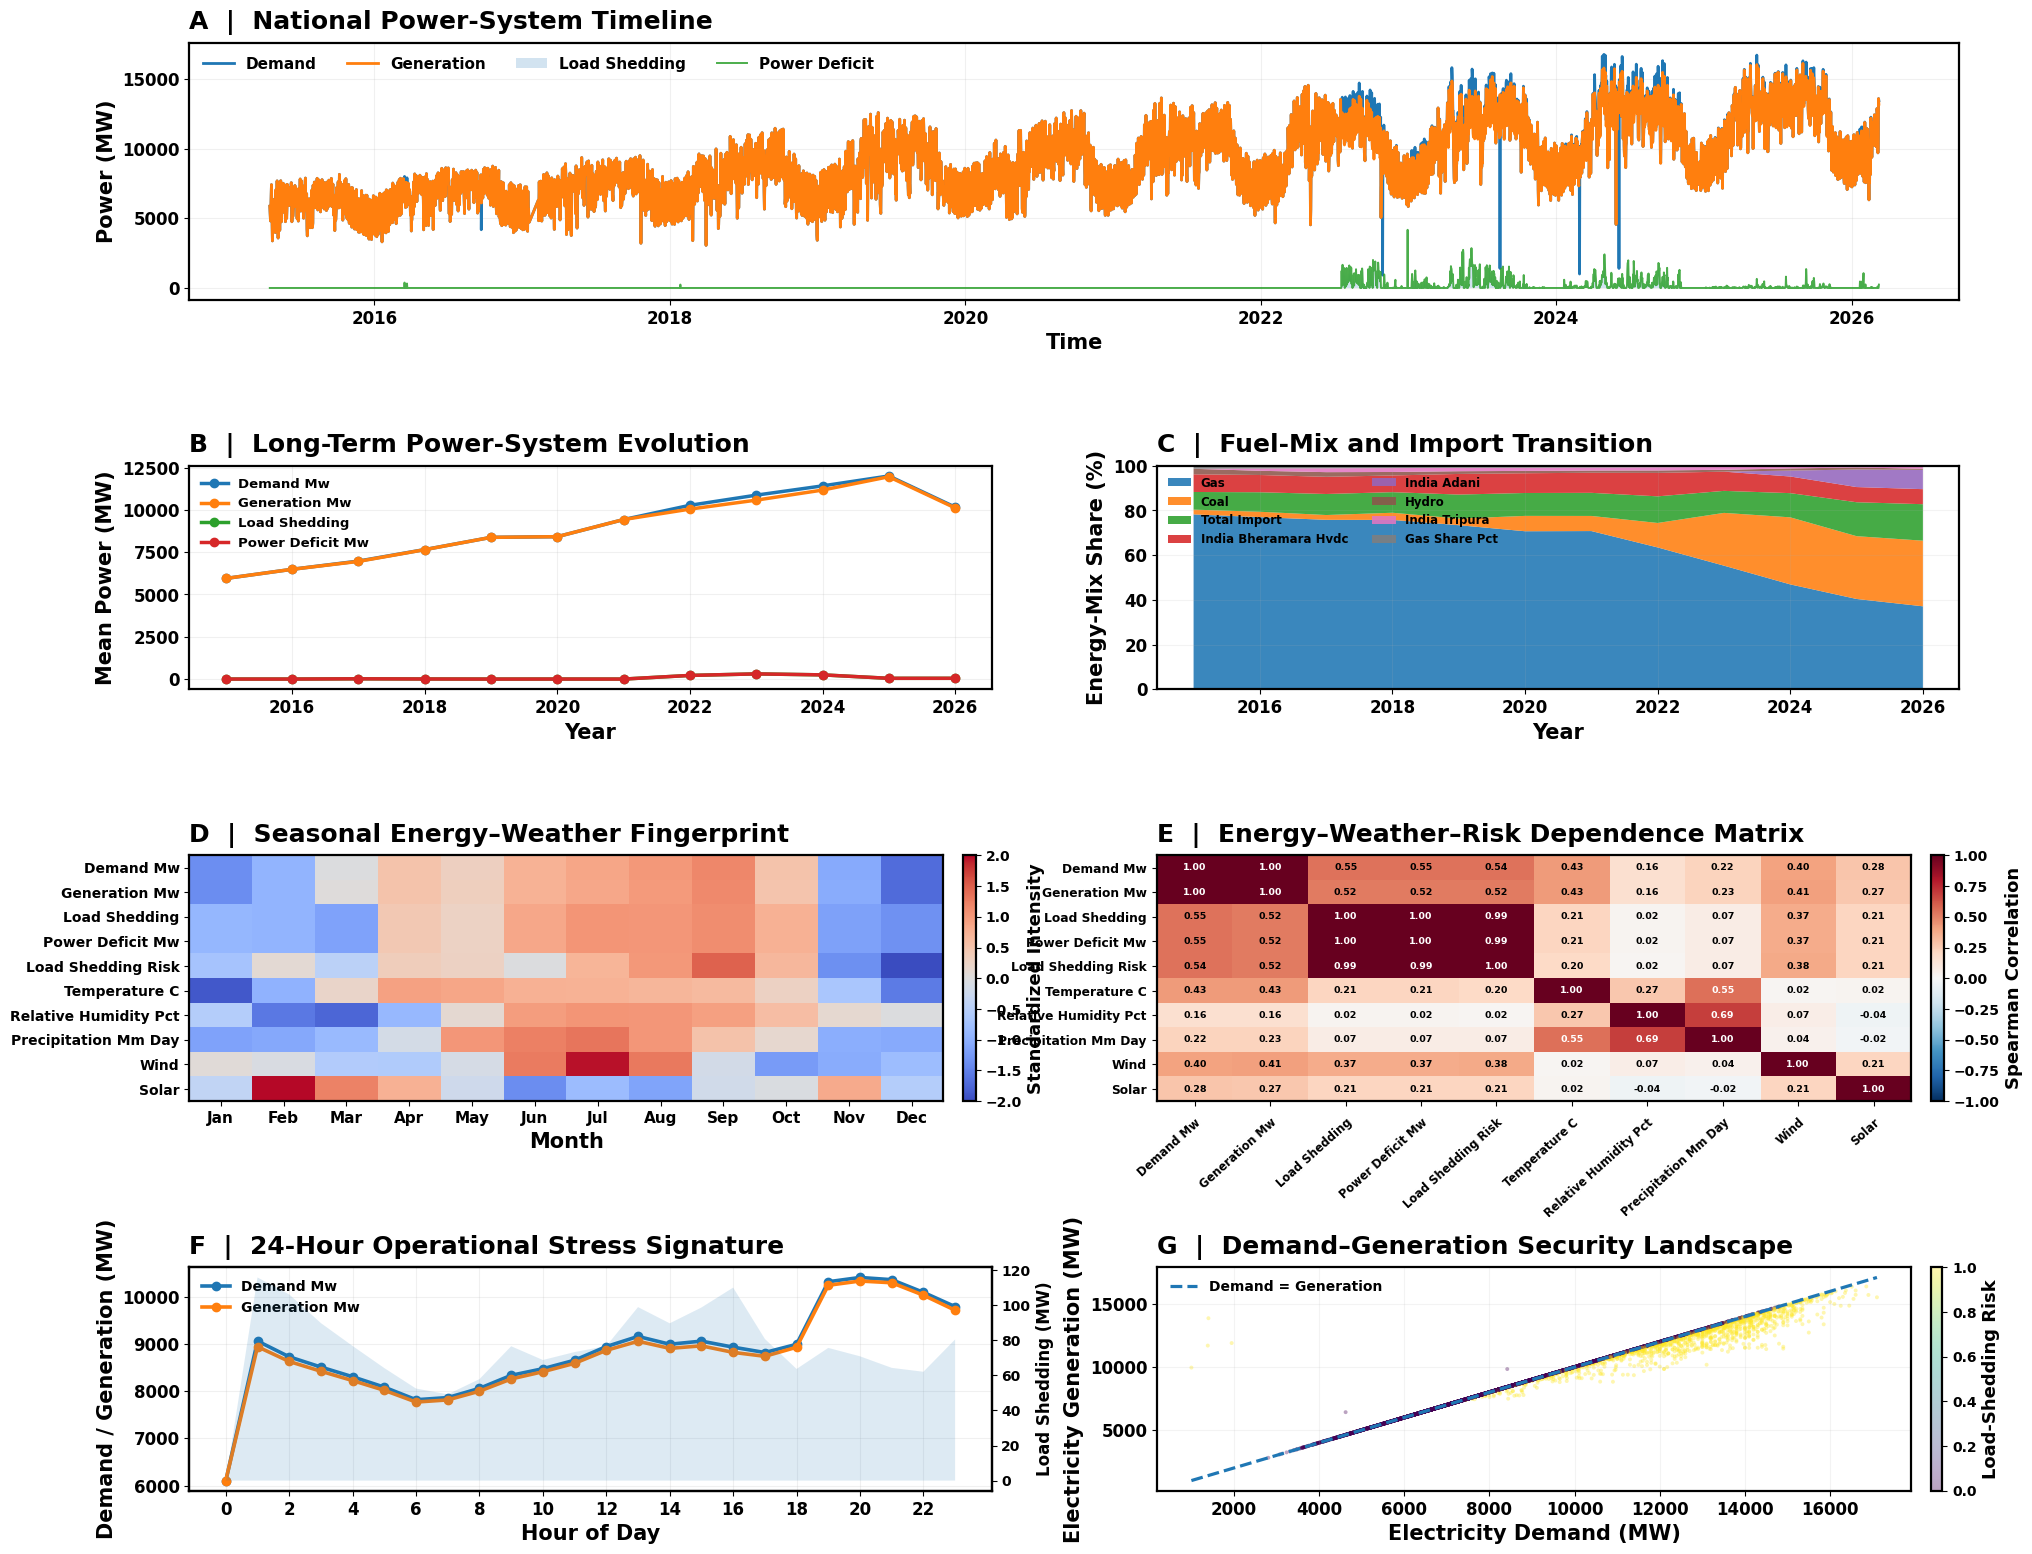

In [4]:
# =====================================================================
# POWERGUARD-BD FULL DATASET STORY MAP
# FINAL VERSION:
# - Standalone
# - Loads dataset automatically
# - Shows figure INSIDE Jupyter Notebook
# - Saves 600 DPI PNG
# - No top main title / no summary line
# - Larger bold text
# - Fixed E-panel overlap
# =====================================================================

import os
import gc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")

# =====================================================================
# 1. LOAD DATASET
# =====================================================================

candidate_paths = [
    r"E:\P work\journal work-2\Final data.csv",
    r"E:\P work\journal work-2\PowerGuard_BD_Merged_Research_Dataset.csv",
    "Final data.csv",
    "PowerGuard_BD_Merged_Research_Dataset.csv",
]

DATA_PATH = None

for p in candidate_paths:
    if Path(p).exists():
        DATA_PATH = Path(p)
        break

if DATA_PATH is None:
    csv_files = list(Path(".").glob("*.csv"))

    if len(csv_files) == 1:
        DATA_PATH = csv_files[0]

    elif len(csv_files) > 1:
        preferred = [
            p for p in csv_files
            if any(
                k in p.name.lower()
                for k in ["final", "powerguard", "merged"]
            )
        ]

        if preferred:
            DATA_PATH = preferred[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset পাওয়া যায়নি। DATA_PATH manually set করুন."
    )

print("Loading dataset:", DATA_PATH)

df = pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset loaded:", df.shape)

D = df.copy()

# =====================================================================
# 2. COLUMN DETECTION
# =====================================================================

lower_map = {
    str(c).lower().strip(): c
    for c in D.columns
}

def find_exact(candidates):
    for c in candidates:
        if c.lower() in lower_map:
            return lower_map[c.lower()]
    return None

def find_keywords(include, exclude=None):
    exclude = exclude or []

    for c in D.columns:
        lc = str(c).lower()

        if (
            all(k.lower() in lc for k in include)
            and not any(e.lower() in lc for e in exclude)
        ):
            return c

    return None

# datetime
dt_col = find_exact([
    "datetime",
    "timestamp",
    "date_time",
    "date",
    "time"
])

if dt_col is None:

    for c in D.columns:

        lc = str(c).lower()

        if (
            "date" in lc
            or "time" in lc
        ):

            test = pd.to_datetime(
                D[c],
                errors="coerce"
            )

            if test.notna().mean() > 0.80:
                dt_col = c
                break

if dt_col is None:
    raise ValueError(
        "Datetime column পাওয়া যায়নি."
    )

D[dt_col] = pd.to_datetime(
    D[dt_col],
    errors="coerce"
)

D = (
    D.dropna(subset=[dt_col])
     .sort_values(dt_col)
     .reset_index(drop=True)
)

# main variables
demand_col = find_exact([
    "demand_mw",
    "electricity_demand_mw",
    "demand",
    "load_demand_mw",
    "load_mw",
    "total_demand_mw"
])

if demand_col is None:
    demand_col = find_keywords(
        ["demand"],
        ["lag", "target"]
    )

generation_col = find_exact([
    "generation_mw",
    "total_generation_mw",
    "electricity_generation_mw",
    "generation",
    "total_generation"
])

if generation_col is None:
    generation_col = find_keywords(
        ["generation"],
        [
            "lag",
            "gas",
            "coal",
            "solar",
            "wind",
            "hydro",
            "oil",
            "import"
        ]
    )

shed_col = find_exact([
    "load_shedding_mw",
    "load_shedding",
    "loadshedding_mw",
    "load_shed_mw"
])

if shed_col is None:
    shed_col = find_keywords(
        ["shedding"],
        ["risk", "target", "lag"]
    )

deficit_col = find_exact([
    "power_deficit_mw",
    "deficit_mw",
    "power_deficit",
    "deficit"
])

if deficit_col is None:
    deficit_col = find_keywords(
        ["deficit"],
        ["lag", "target"]
    )

risk_col = find_exact([
    "load_shedding_risk",
    "risk",
    "risk_label",
    "load_shedding_risk_label",
    "risk_target"
])

if risk_col is None:
    risk_col = find_keywords(
        ["risk"],
        ["lag", "prob"]
    )

# =====================================================================
# 3. WEATHER VARIABLES
# =====================================================================

temp_col = find_exact([
    "T2M",
    "temperature",
    "temperature_c",
    "temp_c",
    "temp"
])

if temp_col is None:
    temp_col = find_keywords(
        ["temp"],
        ["lag"]
    )

humidity_col = find_exact([
    "RH2M",
    "humidity",
    "relative_humidity",
    "humidity_pct"
])

if humidity_col is None:
    humidity_col = find_keywords(
        ["humid"],
        ["lag"]
    )

rain_col = find_exact([
    "PRECTOTCORR",
    "precipitation",
    "rainfall",
    "rainfall_mm"
])

if rain_col is None:
    rain_col = find_keywords(
        ["precip"],
        ["lag"]
    )

if rain_col is None:
    rain_col = find_keywords(
        ["rain"],
        ["lag"]
    )

wind_col = find_exact([
    "WS10M",
    "wind_speed",
    "wind_speed_ms"
])

if wind_col is None:
    wind_col = find_keywords(
        ["wind"],
        ["generation", "mw", "lag"]
    )

solar_weather_col = find_exact([
    "ALLSKY_SFC_SW_DWN",
    "solar_radiation",
    "solar_irradiance"
])

if solar_weather_col is None:
    solar_weather_col = find_keywords(
        ["solar"],
        ["generation", "mw", "lag"]
    )

# =====================================================================
# 4. FUEL MIX
# =====================================================================

fuel_keywords = [
    "gas",
    "coal",
    "oil",
    "diesel",
    "hfo",
    "hydro",
    "solar",
    "wind",
    "nuclear",
    "import",
    "india",
    "nepal"
]

fuel_cols = []

for c in D.columns:

    if not pd.api.types.is_numeric_dtype(D[c]):
        continue

    lc = str(c).lower()

    if any(k in lc for k in fuel_keywords):

        if any(
            x in lc
            for x in [
                "lag",
                "rolling",
                "missing",
                "flag",
                "risk",
                "temperature",
                "humidity",
                "radiation",
                "irradiance",
                "speed"
            ]
        ):
            continue

        if c not in [
            demand_col,
            generation_col,
            shed_col,
            deficit_col,
            risk_col
        ]:
            fuel_cols.append(c)

fuel_cols = list(
    dict.fromkeys(fuel_cols)
)

if fuel_cols:

    fuel_strength = {
        c: pd.to_numeric(
            D[c],
            errors="coerce"
        ).abs().mean()
        for c in fuel_cols
    }

    fuel_cols = sorted(
        fuel_cols,
        key=lambda c: fuel_strength.get(c, 0),
        reverse=True
    )[:8]

# =====================================================================
# 5. TIME FEATURES
# =====================================================================

D["_year"] = D[dt_col].dt.year
D["_month"] = D[dt_col].dt.month
D["_hour"] = D[dt_col].dt.hour

# Plotting subsample for speed only
plot_step = max(
    1,
    int(np.ceil(len(D) / 5000))
)

DP = D.iloc[::plot_step].copy()

scatter_n = min(
    8000,
    len(D)
)

scatter_idx = np.linspace(
    0,
    len(D) - 1,
    scatter_n,
    dtype=int
)

DS = D.iloc[scatter_idx].copy()

# =====================================================================
# 6. STYLE
# =====================================================================

mpl.rcParams.update({

    "font.family": "DejaVu Sans",
    "font.size": 14,
    "font.weight": "bold",

    "axes.titleweight": "bold",
    "axes.labelweight": "bold",

    "axes.titlesize": 17,
    "axes.labelsize": 15,

    "xtick.labelsize": 12,
    "ytick.labelsize": 12,

    "legend.fontsize": 10,

    "axes.linewidth": 1.6,
    "lines.linewidth": 2.2,

    "figure.facecolor": "white",
    "axes.facecolor": "white",

    "savefig.facecolor": "white"
})

# =====================================================================
# 7. FIGURE
# =====================================================================

fig = plt.figure(
    figsize=(20, 16),
    constrained_layout=False
)

gs = GridSpec(
    4,
    4,
    figure=fig,
    height_ratios=[
        1.15,
        1.00,
        1.10,
        1.00
    ],
    hspace=0.70,
    wspace=0.52
)

# =====================================================================
# A. NATIONAL POWER TIMELINE
# =====================================================================

axA = fig.add_subplot(
    gs[0, :]
)

if demand_col is not None:

    axA.plot(
        DP[dt_col],
        pd.to_numeric(
            DP[demand_col],
            errors="coerce"
        ),
        label="Demand",
        linewidth=2.0
    )

if generation_col is not None:

    axA.plot(
        DP[dt_col],
        pd.to_numeric(
            DP[generation_col],
            errors="coerce"
        ),
        label="Generation",
        linewidth=2.0
    )

if shed_col is not None:

    axA.fill_between(
        DP[dt_col],
        0,
        pd.to_numeric(
            DP[shed_col],
            errors="coerce"
        ).fillna(0).clip(lower=0),
        alpha=0.20,
        label="Load Shedding"
    )

if deficit_col is not None:

    axA.plot(
        DP[dt_col],
        pd.to_numeric(
            DP[deficit_col],
            errors="coerce"
        ),
        linewidth=1.4,
        alpha=0.85,
        label="Power Deficit"
    )

axA.set_title(
    "A  |  National Power-System Timeline",
    loc="left",
    fontsize=18,
    pad=10
)

axA.set_ylabel(
    "Power (MW)",
    fontsize=15
)

axA.set_xlabel(
    "Time",
    fontsize=15
)

axA.tick_params(
    labelsize=12
)

axA.grid(
    alpha=0.18
)

axA.legend(
    ncol=4,
    frameon=False,
    loc="upper left",
    prop={
        "weight": "bold",
        "size": 11
    }
)

# =====================================================================
# B. LONG-TERM EVOLUTION
# =====================================================================

axB = fig.add_subplot(
    gs[1, :2]
)

annual_cols = [
    c
    for c in [
        demand_col,
        generation_col,
        shed_col,
        deficit_col
    ]
    if c is not None
]

if annual_cols:

    annual = (
        D.groupby("_year")[annual_cols]
        .mean(numeric_only=True)
    )

    for c in annual.columns:

        axB.plot(
            annual.index,
            annual[c],
            marker="o",
            markersize=6,
            linewidth=2.5,
            label=str(c)
            .replace("_", " ")
            .title()
        )

axB.set_title(
    "B  |  Long-Term Power-System Evolution",
    loc="left",
    fontsize=18,
    pad=10
)

axB.set_xlabel(
    "Year",
    fontsize=15
)

axB.set_ylabel(
    "Mean Power (MW)",
    fontsize=15
)

axB.tick_params(
    labelsize=12
)

axB.xaxis.set_major_locator(
    MaxNLocator(integer=True)
)

axB.grid(
    alpha=0.18
)

axB.legend(
    frameon=False,
    prop={
        "weight": "bold",
        "size": 9.5
    }
)

# =====================================================================
# C. FUEL MIX
# =====================================================================

axC = fig.add_subplot(
    gs[1, 2:]
)

if len(fuel_cols) >= 2:

    fuel_year = (
        D.groupby("_year")[fuel_cols]
        .mean(numeric_only=True)
        .clip(lower=0)
    )

    fuel_share = (
        fuel_year.div(
            fuel_year.sum(axis=1)
            .replace(0, np.nan),
            axis=0
        ) * 100
    ).fillna(0)

    axC.stackplot(
        fuel_share.index,
        *[
            fuel_share[c].values
            for c in fuel_share.columns
        ],
        labels=[
            str(c)
            .replace("_mw", "")
            .replace("_", " ")
            .title()
            for c in fuel_share.columns
        ],
        alpha=0.88
    )

    axC.set_ylim(
        0,
        100
    )

    axC.legend(
        ncol=2,
        fontsize=8.5,
        frameon=False,
        loc="upper left"
    )

else:

    axC.text(
        0.5,
        0.5,
        "Fuel-mix variables not detected",
        ha="center",
        va="center",
        transform=axC.transAxes,
        fontsize=14,
        fontweight="bold"
    )

axC.set_title(
    "C  |  Fuel-Mix and Import Transition",
    loc="left",
    fontsize=18,
    pad=10
)

axC.set_xlabel(
    "Year",
    fontsize=15
)

axC.set_ylabel(
    "Energy-Mix Share (%)",
    fontsize=15
)

axC.tick_params(
    labelsize=12
)

axC.grid(
    alpha=0.14
)

# =====================================================================
# D. SEASONAL ENERGY-WEATHER FINGERPRINT
# =====================================================================

axD = fig.add_subplot(
    gs[2, :2]
)

weather_cols = [
    c
    for c in [
        temp_col,
        humidity_col,
        rain_col,
        wind_col,
        solar_weather_col
    ]
    if c is not None
]

heat_cols = []

for c in [
    demand_col,
    generation_col,
    shed_col,
    deficit_col,
    risk_col
] + weather_cols:

    if (
        c is not None
        and c in D.columns
        and pd.api.types.is_numeric_dtype(D[c])
        and c not in heat_cols
    ):
        heat_cols.append(c)

if heat_cols:

    monthly = (
        D.groupby("_month")[heat_cols]
        .mean(numeric_only=True)
    )

    Z = monthly.copy()

    for c in Z.columns:

        s = Z[c].std()

        if (
            pd.isna(s)
            or s == 0
        ):
            Z[c] = 0

        else:

            Z[c] = (
                Z[c]
                - Z[c].mean()
            ) / s

    imD = axD.imshow(
        Z.T.values,
        aspect="auto",
        interpolation="nearest",
        cmap="coolwarm",
        vmin=-2,
        vmax=2
    )

    axD.set_xticks(
        np.arange(12)
    )

    axD.set_xticklabels([
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ])

    axD.set_yticks(
        np.arange(len(Z.columns))
    )

    axD.set_yticklabels([
        str(c)
        .replace("_", " ")
        .replace("mw", "MW")
        .title()
        for c in Z.columns
    ])

    for lbl in axD.get_xticklabels():
        lbl.set_fontweight("bold")
        lbl.set_fontsize(11)

    for lbl in axD.get_yticklabels():
        lbl.set_fontweight("bold")
        lbl.set_fontsize(10)

    cbD = fig.colorbar(
        imD,
        ax=axD,
        fraction=0.035,
        pad=0.025
    )

    cbD.set_label(
        "Standardized Intensity",
        fontsize=13,
        fontweight="bold"
    )

    cbD.ax.tick_params(
        labelsize=10
    )

axD.set_title(
    "D  |  Seasonal Energy–Weather Fingerprint",
    loc="left",
    fontsize=18,
    pad=10
)

axD.set_xlabel(
    "Month",
    fontsize=15
)

# =====================================================================
# E. DEPENDENCE MATRIX
# =====================================================================

axE = fig.add_subplot(
    gs[2, 2:]
)

corr_cols = []

for c in [
    demand_col,
    generation_col,
    shed_col,
    deficit_col,
    risk_col,
    temp_col,
    humidity_col,
    rain_col,
    wind_col,
    solar_weather_col
] + fuel_cols:

    if (
        c is not None
        and c in D.columns
        and pd.api.types.is_numeric_dtype(D[c])
        and c not in corr_cols
    ):
        corr_cols.append(c)

corr_cols = corr_cols[:10]

if len(corr_cols) >= 2:

    C = D[corr_cols].corr(
        method="spearman"
    )

    imE = axE.imshow(
        C.values,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        aspect="auto"
    )

    labels = [
        str(c)
        .replace("_", " ")
        .replace("mw", "MW")
        .title()
        for c in C.columns
    ]

    axE.set_xticks(
        np.arange(len(labels))
    )

    axE.set_yticks(
        np.arange(len(labels))
    )

    axE.set_xticklabels(
        labels,
        rotation=42,
        ha="right",
        rotation_mode="anchor",
        fontsize=8.3,
        fontweight="bold"
    )

    axE.set_yticklabels(
        labels,
        fontsize=8.8,
        fontweight="bold"
    )

    axE.tick_params(
        axis="x",
        pad=7
    )

    axE.tick_params(
        axis="y",
        pad=4
    )

    for i in range(len(C)):
        for j in range(len(C)):

            val = C.iloc[i, j]

            axE.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                fontsize=6.8,
                fontweight="bold",
                color=(
                    "white"
                    if abs(val) > 0.55
                    else "black"
                )
            )

    cbE = fig.colorbar(
        imE,
        ax=axE,
        fraction=0.035,
        pad=0.025
    )

    cbE.set_label(
        "Spearman Correlation",
        fontsize=13,
        fontweight="bold"
    )

    cbE.ax.tick_params(
        labelsize=10
    )

axE.set_title(
    "E  |  Energy–Weather–Risk Dependence Matrix",
    loc="left",
    fontsize=18,
    pad=10
)

# =====================================================================
# F. 24-HOUR OPERATIONAL STRESS
# =====================================================================

axF = fig.add_subplot(
    gs[3, :2]
)

hour_cols = [
    c
    for c in [
        demand_col,
        generation_col
    ]
    if c is not None
]

if hour_cols:

    hourly = (
        D.groupby("_hour")[hour_cols]
        .mean(numeric_only=True)
    )

    for c in hourly.columns:

        axF.plot(
            hourly.index,
            hourly[c],
            marker="o",
            markersize=6,
            linewidth=2.6,
            label=str(c)
            .replace("_", " ")
            .title()
        )

if shed_col is not None:

    axF2 = axF.twinx()

    shed_hourly = (
        D.groupby("_hour")[shed_col]
        .mean()
    )

    axF2.fill_between(
        shed_hourly.index,
        0,
        shed_hourly.values,
        alpha=0.15
    )

    axF2.set_ylabel(
        "Load Shedding (MW)",
        fontsize=12,
        fontweight="bold"
    )

    axF2.tick_params(
        labelsize=10
    )

axF.set_title(
    "F  |  24-Hour Operational Stress Signature",
    loc="left",
    fontsize=18,
    pad=10
)

axF.set_xlabel(
    "Hour of Day",
    fontsize=15
)

axF.set_ylabel(
    "Demand / Generation (MW)",
    fontsize=15
)

axF.set_xticks(
    np.arange(0, 24, 2)
)

axF.tick_params(
    labelsize=12
)

axF.grid(
    alpha=0.18
)

axF.legend(
    frameon=False,
    prop={
        "weight": "bold",
        "size": 10
    }
)

# =====================================================================
# G. SECURITY LANDSCAPE
# =====================================================================

axG = fig.add_subplot(
    gs[3, 2:]
)

if (
    demand_col is not None
    and generation_col is not None
):

    x = pd.to_numeric(
        DS[demand_col],
        errors="coerce"
    ).to_numpy()

    y = pd.to_numeric(
        DS[generation_col],
        errors="coerce"
    ).to_numpy()

    valid = (
        np.isfinite(x)
        & np.isfinite(y)
    )

    x = x[valid]
    y = y[valid]

    if risk_col is not None:

        cv = pd.to_numeric(
            DS.loc[valid, risk_col],
            errors="coerce"
        ).fillna(0).to_numpy()

        sc = axG.scatter(
            x,
            y,
            c=cv,
            s=8,
            alpha=0.36,
            cmap="viridis",
            linewidths=0,
            rasterized=True
        )

        cbG = fig.colorbar(
            sc,
            ax=axG,
            fraction=0.035,
            pad=0.025
        )

        cbG.set_label(
            "Load-Shedding Risk",
            fontsize=13,
            fontweight="bold"
        )

        cbG.ax.tick_params(
            labelsize=10
        )

    elif deficit_col is not None:

        cv = pd.to_numeric(
            DS.loc[valid, deficit_col],
            errors="coerce"
        ).fillna(0).to_numpy()

        sc = axG.scatter(
            x,
            y,
            c=cv,
            s=8,
            alpha=0.36,
            cmap="viridis",
            linewidths=0,
            rasterized=True
        )

    else:

        axG.scatter(
            x,
            y,
            s=8,
            alpha=0.30,
            linewidths=0,
            rasterized=True
        )

    mn = np.nanmin([
        np.nanmin(x),
        np.nanmin(y)
    ])

    mx = np.nanmax([
        np.nanmax(x),
        np.nanmax(y)
    ])

    axG.plot(
        [mn, mx],
        [mn, mx],
        "--",
        linewidth=2.3,
        label="Demand = Generation"
    )

axG.set_title(
    "G  |  Demand–Generation Security Landscape",
    loc="left",
    fontsize=18,
    pad=10
)

axG.set_xlabel(
    "Electricity Demand (MW)",
    fontsize=15
)

axG.set_ylabel(
    "Electricity Generation (MW)",
    fontsize=15
)

axG.tick_params(
    labelsize=12
)

axG.grid(
    alpha=0.15
)

axG.legend(
    frameon=False,
    prop={
        "weight": "bold",
        "size": 10
    }
)

# =====================================================================
# 8. FINAL SPACING
# =====================================================================

plt.subplots_adjust(
    top=0.975,
    bottom=0.07,
    left=0.07,
    right=0.955,
    hspace=0.70,
    wspace=0.52
)

# =====================================================================
# 9. SAVE
# =====================================================================

OUT_DIR = Path(
    "PowerGuard_BD_Publication_Figures"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

out_png = (
    OUT_DIR /
    "Fig_PowerGuard_BD_FULL_DATASET_STORY_MAP_FINAL_600DPI.png"
)

fig.savefig(
    out_png,
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.08,
    facecolor="white",
    edgecolor="none"
)

# =====================================================================
# 10. FORCE DISPLAY INSIDE JUPYTER
# =====================================================================

from IPython.display import display

display(fig)

print(
    "\nSaved:",
    out_png
)

print(
    f"File size: "
    f"{out_png.stat().st_size / (1024**2):.2f} MB"
)

# IMPORTANT:
# Do NOT close figure before display.
# plt.close(fig) দিলে notebook-এ figure আর show নাও করতে পারে.